In [ ]:
# setup
# Colab: select a GPU runtime, then Run all. No Drive login is required.
import os, sys, subprocess, importlib.util
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
for package in ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scipy', 'tqdm']:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
if importlib.util.find_spec('torch') is None or importlib.util.find_spec('torchvision') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torch', 'torchvision'])

import copy, gc, hashlib, inspect, io, json, math, random, time, warnings
from pathlib import Path
from collections import OrderedDict
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import torch
from torch import nn
import torch.nn.functional as F
from torch.func import functional_call
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from IPython.display import display
from tqdm.auto import tqdm

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))
if DEVICE.type == 'cpu' and hasattr(torch.backends, 'nnpack'):
    torch.backends.nnpack.set_flags(False)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 200, 'axes.spines.top': False,
                     'axes.spines.right': False})
print({'device': str(DEVICE), 'torch': torch.__version__,
       'GPU': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})


{'device': 'cuda', 'torch': '2.11.0+cu130', 'GPU': 'Tesla T4'}


In [ ]:
# configuration
@dataclass
class Settings:
    datasets: tuple = ('MNIST','FashionMNIST','KMNIST')
    seeds: tuple = (0,1,2)
    baselines: tuple = ('L1','FPGM','Taylor','HRank','Reconstruction')
    keep_ratio: float = 0.50
    base_width: int = 16
    blocks_per_stage: int = 1
    teacher_epochs: int = 12
    teacher_lr: float = 0.10
    recovery_epochs: int = 6
    clean_tail_epochs: int = 1
    recovery_lr: float = 0.015
    clean_tail_lr: float = 0.003
    clean_loss_weight: float = 0.65
    batch_size: int = 256
    eval_batch: int = 512
    workers: int = 0
    val_fraction: float = 0.10
    train_limit: int = 0
    validation_limit: int = 0
    test_limit: int = 0
    reconstruction_examples: int = 512
    reconstruction_batch: int = 64
    reconstruction_points: int = 8
    reconstruction_ridge: float = 0.001
    domain_temperature: float = 0.10
    clean_domain_anchor: float = 0.25
    domain_mix: float = 0.50
    refit_iterations: int = 8
    kd_weight: float = 0.70
    temperature: float = 3.0
    reliable_confidence: float = 0.65
    clean_feature_weight: float = 0.20
    shift_feature_weight: float = 0.05
    feature_warmup: int = 2
    bn_batches: int = 16
    selection_examples: int = 0
    risk_weights: tuple = (0.50,0.35,0.15)
    fresh_test_seed: int = 20261011
    test_shifts: tuple = ('blur','impulse','pixelate','fog','motion','occlusion')
    severities: tuple = (1,3)
    latency_repeats: int = 7
    latency_iterations: int = 40
    latency_batches: tuple = (1,32,256)
    run_experiments: bool = True

CFG = Settings()
ROOT=Path('./LRP_Compression'); ROOT.mkdir(parents=True,exist_ok=True)
DATA_ROOT=Path('./LRP_data'); DATA_ROOT.mkdir(parents=True,exist_ok=True)
assert 1<=len(CFG.seeds)<=3 and len(set(CFG.seeds))==len(CFG.seeds)
assert set(CFG.datasets)<= {'MNIST','FashionMNIST','KMNIST'} and CFG.datasets
assert set(CFG.baselines)<= {'L1','FPGM','Taylor','HRank','Reconstruction'}
assert len(set(CFG.baselines))==len(CFG.baselines)
assert 0<CFG.keep_ratio<1 and CFG.teacher_epochs>=1
assert 0<CFG.clean_tail_epochs<CFG.recovery_epochs and 0<CFG.clean_loss_weight<1
assert 0<=CFG.clean_domain_anchor and 0<=CFG.domain_mix and CFG.clean_domain_anchor+CFG.domain_mix<1
assert CFG.reconstruction_ridge>0 and CFG.domain_temperature>0 and CFG.refit_iterations>=1
assert CFG.reconstruction_examples>=10 and CFG.reconstruction_points>=1
assert 0<=CFG.kd_weight<=1 and 0<=CFG.reliable_confidence<=1
assert min(CFG.risk_weights)>=0 and abs(sum(CFG.risk_weights)-1)<1e-8
assert CFG.latency_repeats>=3 and CFG.latency_iterations>=1 and min(CFG.latency_batches)>=1
METHODS=('Teacher','Dense recovery',*CFG.baselines,'LRP')
COMPRESSED=(*CFG.baselines,'LRP')
print('One LRP configuration; five pruning baselines; matched dense recovery control.')
print('Training:',DEVICE,'| reconstruction and rank calculations: CPU')
print('Compatible saved dense teachers are reused. All reported target results are recomputed.')


One LRP configuration; five pruning baselines; matched dense recovery control.
Training: cuda | reconstruction and rank calculations: CPU
Compatible saved dense teachers are reused. All reported target results are recomputed.


In [ ]:
PIPELINE_CODE_HASH = 'f67df7c724a1f14a053911403b849b2b89ccfcb2d7a142ad103d81406b82e0c7'
# utilities
COMPATIBLE_TEACHER_CACHES = {'b5c700b020816fbe': '94d20119d254480b', 'dd31821ce517d7a2': 'b8ada4f4f1859a62'}
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def stable_seed(*parts):
    return int(hashlib.sha256('|'.join(map(str, parts)).encode()).hexdigest()[:8], 16) % (2**31)

def synchronize():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

def cpu_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

def atomic_torch(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    torch.save(obj, tmp); os.replace(tmp, path)

def atomic_json(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, indent=2, allow_nan=False)); os.replace(tmp, path)

def load_checkpoint(path):
    return torch.load(path, map_location='cpu', weights_only=False)  # Own checkpoints only.

def finite(loss, label):
    if not bool(torch.isfinite(loss).all()):
        raise FloatingPointError(f'Non-finite {label}; checkpoint retained for inspection.')


In [ ]:
# real datasets
class ArrayData(Dataset):
    def __init__(self, images, labels, ids):
        self.images, self.labels = images, labels
        self.ids = np.asarray(ids, dtype=np.int64)
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        j = int(self.ids[i])
        return torch.from_numpy(self.images[j].copy()), int(self.labels[j])

def stratified_ids(labels, fraction, seed):
    rng = np.random.default_rng(seed); left, right = [], []
    for c in np.unique(labels):
        ids = np.flatnonzero(labels == c); rng.shuffle(ids)
        n = max(1, min(len(ids)-1, int(round(len(ids)*fraction))))
        right.extend(ids[:n]); left.extend(ids[n:])
    rng.shuffle(left); rng.shuffle(right)
    return np.asarray(left), np.asarray(right)

def balanced_limit(ids, labels, limit, seed):
    if not limit or len(ids) <= limit: return np.asarray(ids)
    rng = np.random.default_rng(seed)
    groups = [rng.permutation(ids[labels[ids] == c]) for c in np.unique(labels[ids])]
    # Round-robin selection retains every available class.
    out = []
    for i in range(max(map(len, groups))):
        for g in groups:
            if i < len(g): out.append(g[i])
            if len(out) == limit: return rng.permutation(out)
    return rng.permutation(out)

def verified_download(urls, folder, filename, md5):
    import urllib.request
    folder=Path(folder); folder.mkdir(parents=True,exist_ok=True)
    target=folder/filename
    def valid(path):
        if not path.exists(): return False
        digest=hashlib.md5()
        with path.open('rb') as f:
            for chunk in iter(lambda:f.read(1024*1024),b''): digest.update(chunk)
        return digest.hexdigest()==md5
    if valid(target): return
    errors=[]
    for url in urls:
        temporary=target.with_suffix(target.suffix+'.partial')
        try:
            request=urllib.request.Request(url,headers={'User-Agent':'Mozilla/5.0'})
            with urllib.request.urlopen(request,timeout=45) as response, temporary.open('wb') as f:
                total=int(response.headers.get('Content-Length',0))
                with tqdm(total=total or None,unit='B',unit_scale=True,desc=filename) as bar:
                    while True:
                        chunk=response.read(1024*1024)
                        if not chunk: break
                        f.write(chunk); bar.update(len(chunk))
            if not valid(temporary): raise RuntimeError('Dataset checksum mismatch')
            os.replace(temporary,target); return
        except Exception as exc:
            temporary.unlink(missing_ok=True); errors.append(f'{url}: {exc}')
    raise RuntimeError('Dataset download failed; rerun this cell.\n'+'\n'.join(errors))

def get_arrays(name):
    if name not in ('MNIST','FashionMNIST','KMNIST'): raise ValueError(name)
    cls=getattr(datasets,name)
    try:
        train=cls(DATA_ROOT,train=True,download=False)
        test=cls(DATA_ROOT,train=False,download=False)
    except RuntimeError:
        from torchvision.datasets.utils import extract_archive
        raw=DATA_ROOT/name/'raw'
        for filename,md5 in cls.resources:
            mirrors=[]
            if name=='FashionMNIST':
                mirrors.append('https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/')
            elif name=='KMNIST':
                # Original archives, pinned mirror revision; upstream MD5 checks remain mandatory.
                mirrors.append('https://huggingface.co/datasets/tanganke/kmnist/resolve/'
                               'c069cb84fc8b936f73c01c933a54fc57345a9c87/raw/')
            mirrors.extend(m.replace('http://','https://') for m in cls.mirrors)
            mirrors.extend(cls.mirrors)
            urls=list(dict.fromkeys(m+filename for m in mirrors))
            verified_download(urls,raw,filename,md5)
            extract_archive(str(raw/filename),str(raw))
        train=cls(DATA_ROOT,train=True,download=False)
        test=cls(DATA_ROOT,train=False,download=False)
    a=(np.asarray(train.data)[:,None,:,:],np.asarray(train.targets),
       np.asarray(test.data)[:,None,:,:],np.asarray(test.targets))
    assert a[0].shape[1:]==(1,28,28) and a[2].shape[1:]==(1,28,28)
    return tuple(np.ascontiguousarray(v) for v in a)

def loader(ds, batch=None, shuffle=False, seed=0):
    return DataLoader(ds, batch_size=batch or CFG.batch_size, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed), num_workers=CFG.workers,
                      pin_memory=(DEVICE.type=='cuda'), persistent_workers=False, drop_last=False)

def unpack(batch):
    x,y = batch
    return x.to(DEVICE, non_blocking=True).float()/255., y.to(DEVICE, non_blocking=True)

def augment(x, name):
    n, _, h, w = x.shape
    # Small translations only; flipping digits or Japanese characters changes their meaning.
    padded = F.pad(x, (2,2,2,2), mode='constant', value=0)
    oy = torch.randint(0,5,(n,1,1), device=x.device)
    ox = torch.randint(0,5,(n,1,1), device=x.device)
    yy = torch.arange(h,device=x.device)[None,:,None] + oy
    xx = torch.arange(w,device=x.device)[None,None,:] + ox
    x = padded.permute(0,2,3,1)[torch.arange(n,device=x.device)[:,None,None],yy,xx].permute(0,3,1,2)
    return x.contiguous()

def shift(x, kind, severity, seed):
    if kind=='motion':
        k=3+2*int(severity); horizontal=seed%2==0
        pad=(k//2,k//2,0,0) if horizontal else (0,0,k//2,k//2)
        kernel=(1,k) if horizontal else (k,1)
        return F.avg_pool2d(F.pad(x,pad,mode='reflect'),kernel,stride=1).clamp(0,1)
    if kind=='occlusion':
        g=torch.Generator(device=x.device).manual_seed(seed); side=3+2*int(severity)
        oy=torch.randint(0,x.shape[-2]-side+1,(len(x),1,1),generator=g,device=x.device)
        ox=torch.randint(0,x.shape[-1]-side+1,(len(x),1,1),generator=g,device=x.device)
        yy=torch.arange(x.shape[-2],device=x.device)[None,:,None]
        xx=torch.arange(x.shape[-1],device=x.device)[None,None,:]
        mask=((yy>=oy)&(yy<oy+side)&(xx>=ox)&(xx<ox+side))[:,None]
        return torch.where(mask,torch.zeros_like(x),x)
    g = torch.Generator(device=x.device).manual_seed(int(seed))
    s = float(severity)
    if kind == 'clean': return x
    if kind == 'brightness': y = x + .08*s
    elif kind == 'contrast': y = (x-.5)*(1-.18*s)+.5
    elif kind == 'gaussian':
        y = x + torch.randn(x.shape, generator=g, device=x.device, dtype=x.dtype)*(.035*s)
    elif kind == 'blur':
        k = 2*int(s)+1
        y = F.avg_pool2d(F.pad(x,(k//2,)*4, mode='reflect'),k,stride=1)
    elif kind == 'impulse':
        u = torch.rand((len(x),1,x.shape[2],x.shape[3]), generator=g,device=x.device)
        p = .025*s
        y = torch.where(u<p, torch.zeros_like(x), torch.where(u>1-p,torch.ones_like(x),x))
    elif kind == 'pixelate':
        side = max(4, int(x.shape[-1]/(1+s)))
        y = F.interpolate(F.interpolate(x,size=(side,side),mode='area'),size=x.shape[-2:],mode='nearest')
    elif kind == 'fog':
        cloud = torch.rand((len(x),1,4,4),generator=g,device=x.device)
        cloud = F.interpolate(cloud,size=x.shape[-2:],mode='bilinear',align_corners=False)
        alpha = (.12*s + .12*cloud).clamp(0,.75)
        y = x*(1-alpha)+alpha
    else: raise ValueError(kind)
    return y.clamp(0,1)


In [ ]:
# physically prunable network
class ChannelGate(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.register_buffer('mask', torch.ones(width))
        self.logits = nn.Parameter(torch.zeros(width), requires_grad=False)
        self.searching = False
        self.keep = width
    def values(self):
        if not self.searching: return self.mask
        soft = self.logits.sigmoid()
        hard = torch.zeros_like(soft).scatter(0, torch.topk(soft,self.keep).indices,1.)
        return hard.detach()-soft.detach()+soft
    def forward(self,x):
        if not self.searching and self.keep==len(self.mask): return x
        return x*self.values()[None,:,None,None]

class Block(nn.Module):
    def __init__(self, cin, cout, stride=1, hidden=None):
        super().__init__(); hidden = hidden or cout
        self.conv1 = nn.Conv2d(cin,hidden,3,stride,1,bias=False)
        self.bn1 = nn.BatchNorm2d(hidden)
        self.gate = ChannelGate(hidden)
        self.conv2 = nn.Conv2d(hidden,cout,3,1,1,bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = (nn.Identity() if stride==1 and cin==cout else
                         nn.Sequential(nn.Conv2d(cin,cout,1,stride,bias=False),nn.BatchNorm2d(cout)))
    def forward(self,x):
        z = self.gate(F.relu(self.bn1(self.conv1(x)),inplace=False))
        return F.relu(self.bn2(self.conv2(z))+self.shortcut(x),inplace=False)

class SmallResNet(nn.Module):
    def __init__(self, classes, base=16, depth=1, hidden=None):
        super().__init__(); self.spec = {'classes':classes,'base':base,'depth':depth,'hidden':hidden}
        self.stem = nn.Sequential(nn.Conv2d(1,base,3,1,1,bias=False),nn.BatchNorm2d(base),nn.ReLU())
        blocks=[]; cin=base; j=0
        for stage, cout in enumerate([base,base*2,base*4]):
            for b in range(depth):
                blocks.append(Block(cin,cout,2 if stage>0 and b==0 else 1,None if hidden is None else hidden[j]))
                cin=cout; j+=1
        self.blocks=nn.ModuleList(blocks); self.fc=nn.Linear(cin,classes)
        for m in self.modules():
            if isinstance(m,nn.Conv2d): nn.init.kaiming_normal_(m.weight,mode='fan_out',nonlinearity='relu')
            elif isinstance(m,nn.BatchNorm2d): nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    def forward(self,x,features=False):
        x=self.stem((x-.5)/.5); fs=[]
        for block in self.blocks:
            x=block(x)
            if features: fs.append(x)
        z=self.fc(F.adaptive_avg_pool2d(x,1).flatten(1))
        return (z,fs) if features else z

def network(classes):
    return SmallResNet(classes,CFG.base_width,CFG.blocks_per_stage).to(DEVICE)

def norm_names(model):
    names=[]
    for prefix,m in model.named_modules():
        if isinstance(m,nn.BatchNorm2d): names.extend([prefix+'.weight',prefix+'.bias'])
    return names

def freeze_bn(model):
    for m in model.modules():
        if isinstance(m,nn.BatchNorm2d): m.eval()

def kept_width(width, ratio):
    return max(1,min(width,int(round(width*ratio))))

def compact_model(model,indices):
    compact=SmallResNet(model.spec['classes'],model.spec['base'],model.spec['depth'],
                       [len(i) for i in indices]).to(DEVICE)
    src=model.state_dict(); dst=compact.state_dict()
    for key in dst:
        if '.gate.' in key: continue
        if key.startswith('blocks.'):
            j=int(key.split('.')[1]); idx=indices[j].to(DEVICE)
            suffix='.'.join(key.split('.')[2:])
            if suffix=='conv1.weight': value=src[key].index_select(0,idx)
            elif suffix=='conv2.weight': value=src[key].index_select(1,idx)
            elif suffix.startswith('bn1.') and src[key].ndim>0: value=src[key].index_select(0,idx)
            else: value=src[key]
        else: value=src[key]
        dst[key].copy_(value)
    compact.load_state_dict(dst)
    return compact

@torch.no_grad()
def check_surgery(model,indices):
    model=copy.deepcopy(model).eval()
    for b,idx in zip(model.blocks,indices):
        b.gate.searching=False; b.gate.keep=len(idx); b.gate.mask.zero_(); b.gate.mask[idx]=1
    compact=compact_model(model,indices).eval()
    x=torch.rand(3,1,28,28,device=DEVICE)
    err=(model(x)-compact(x)).abs().max().item()
    torch.testing.assert_close(model(x),compact(x),atol=2e-5,rtol=2e-4)
    return compact,err


In [ ]:
# fixed source and untouched target splits
SOURCE_DOMAINS=[('clean',0),('brightness',1),('brightness',3),
                ('contrast',1),('contrast',3),('gaussian',1),('gaussian',3)]
PRIOR_TEST_USAGE={'seeded_samples':{'seeds':[0,1,2],'support':256,'query':2000},
    'fixed_sample':{'seed':20261010,'support':256,'query':2000,
    'query_hash':'07bc13ee3f6f6b7e1b92672054471fc23aae70847313e0b3d56fae9e633b9f00'},
    'reviewed_run':{'seed':20261011,'support':256,'query':1500,
    'query_hash':'8cf9547f415f4b6e1d1e31736c839ab78093bfcb5936b5b0818d78874de72ceb'}}
HARDWARE={'device':str(DEVICE),'GPU':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU',
          'torch':torch.__version__,'python':sys.version.split()[0],
          'reconstruction_device':'cpu','reconstruction_dtype':'float64','rank_device':'cpu'}

def used_test_ids(size):
    used=set(); first=PRIOR_TEST_USAGE['seeded_samples']
    for seed in first['seeds']:
        ids=np.random.default_rng(seed+99).permutation(size)
        used.update(ids[:first['support']+first['query']].tolist())
    for label in ('fixed_sample','reviewed_run'):
        protocol=PRIOR_TEST_USAGE[label]
        remaining=np.array(sorted(set(range(size))-used),dtype=np.int64)
        ids=np.random.default_rng(protocol['seed']).permutation(remaining)
        a=protocol['support']; b=a+protocol['query']
        assert hashlib.sha256(ids[a:b].tobytes()).hexdigest()==protocol['query_hash']
        used.update(ids[:b].tolist())
    return used

def make_data(arrays,seed):
    xtr,ytr,xte,yte=arrays
    fit,val=stratified_ids(ytr,CFG.val_fraction,seed)
    fit=balanced_limit(fit,ytr,CFG.train_limit,seed+11)
    val=balanced_limit(val,ytr,CFG.validation_limit,seed+12)
    first,audit=stratified_ids(ytr[val],1/3,seed+1401)
    reserve,selection=stratified_ids(ytr[val[first]],.5,seed+1402)
    select=val[first[selection]]; audit=np.concatenate([val[audit],val[first[reserve]]])
    assert not set(fit).intersection(val) and not set(select).intersection(audit)
    used=used_test_ids(len(yte)); query=np.array(sorted(set(range(len(yte)))-used),dtype=np.int64)
    query=np.random.default_rng(CFG.fresh_test_seed).permutation(query)
    if CFG.test_limit: query=query[:CFG.test_limit]
    assert len(query)>=32 and not used.intersection(query)
    data={'fit':ArrayData(xtr,ytr,fit),'val':ArrayData(xtr,ytr,val),
          'select':ArrayData(xtr,ytr,select),'audit':ArrayData(xtr,ytr,audit),
          'query':ArrayData(xte,yte,query),'classes':int(ytr.max()+1)}
    data['split_hash']=hashlib.sha256(b''.join(part.tobytes() for part in
        [fit,val,select,audit,query])).hexdigest()
    data['fresh_audit']={'previously_used':len(used),'query':len(query),
        'overlap_with_prior_test_usage':0,'query_ids_sha256':hashlib.sha256(query.tobytes()).hexdigest()}
    return data

def model_from_checkpoint(ck):
    s=ck['spec']; m=SmallResNet(s['classes'],s['base'],s['depth'],s['hidden']).to(DEVICE)
    m.load_state_dict(ck['state']); return m.eval()


In [ ]:
# dense teacher training
@torch.no_grad()
def accuracy(model,ds):
    model.eval(); correct=0; count=0; loss=0.
    for batch in loader(ds,CFG.eval_batch):
        x,y=unpack(batch); z=model(x)
        correct+=z.argmax(-1).eq(y).sum().item(); count+=len(y)
        loss+=F.cross_entropy(z,y,reduction='sum').item()
    return 100*correct/max(count,1),loss/max(count,1)

def train_teacher(model,data,seed,path):
    params=[p for p in model.parameters() if p.requires_grad]
    opt=torch.optim.SGD(params,lr=CFG.teacher_lr,momentum=.9,weight_decay=5e-4)
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,CFG.teacher_epochs)
    best=-1.; best_state=cpu_state(model); start=0; history=[]; seconds=0.
    last=Path(str(path)+'.last.pt')
    if last.exists():
        ck=load_checkpoint(last); model.load_state_dict(ck['state'])
        opt.load_state_dict(ck['optimizer']); sched.load_state_dict(ck['scheduler'])
        for state in opt.state.values():
            for key,value in state.items():
                if torch.is_tensor(value): state[key]=value.to(DEVICE)
        start=ck['epoch']+1; best=ck['best']; best_state=ck['best_state']
        history=ck['history']; seconds=ck['seconds']
    for epoch in range(start,CFG.teacher_epochs):
        seed_all(stable_seed(seed,'epoch',epoch)); synchronize(); began=time.perf_counter()
        model.train(); accumulated=0.; seen=0
        for batch in loader(data['fit'],shuffle=True,seed=stable_seed(seed,epoch)):
            x,y=unpack(batch); x=augment(x,data['name']); opt.zero_grad(set_to_none=True)
            loss=F.cross_entropy(model(x),y,label_smoothing=.05)
            finite(loss,'teacher loss'); loss.backward()
            torch.nn.utils.clip_grad_norm_(params,5.); opt.step()
            accumulated+=float(loss.detach())*len(y); seen+=len(y)
        sched.step(); val_acc,val_ce=accuracy(model,data['val'])
        synchronize(); elapsed=time.perf_counter()-began; seconds+=elapsed
        if val_acc>best: best=val_acc; best_state=cpu_state(model)
        history.append({'epoch':epoch+1,'loss':accumulated/max(seen,1),
                        'val_accuracy':val_acc,'val_ce':val_ce,'seconds':elapsed})
        atomic_torch({'state':cpu_state(model),'spec':model.spec,'epoch':epoch,
            'optimizer':opt.state_dict(),'scheduler':sched.state_dict(),'best':best,
            'best_state':best_state,'history':history,'seconds':seconds},last)
        print(f"{data['name']} seed={seed} Teacher: {epoch+1}/{CFG.teacher_epochs}, "
              f"val={val_acc:.2f}%, {elapsed:.0f}s/epoch",flush=True)
    model.load_state_dict(best_state); model.eval()
    ck={'state':best_state,'spec':model.spec,'history':history,'seconds':seconds}
    atomic_torch(ck,path); last.unlink(missing_ok=True); return model,ck


In [ ]:
# clean-anchored domain weights
def domain_weights(errors):
    uniform=torch.ones_like(errors)/len(errors)
    if len(errors)==1: return uniform
    clean=torch.zeros_like(errors); clean[0]=1.
    worst=torch.zeros_like(errors)
    worst[1:]=torch.softmax(errors[1:].detach()/CFG.domain_temperature,0)
    return ((1-CFG.clean_domain_anchor-CFG.domain_mix)*uniform+
            CFG.clean_domain_anchor*clean+CFG.domain_mix*worst)
@torch.no_grad()
def source_score(model,data,seed):
    model.eval(); ds=data['select']
    if CFG.selection_examples:
        ids=balanced_limit(ds.ids,ds.labels,CFG.selection_examples,stable_seed(seed,'selection'))
        ds=ArrayData(ds.images,ds.labels,ids)
    correct=np.zeros(len(SOURCE_DOMAINS)); losses=correct.copy(); count=0
    for i,batch in enumerate(loader(ds,CFG.eval_batch)):
        x,y=unpack(batch); count+=len(y)
        for j,(kind,severity) in enumerate(SOURCE_DOMAINS):
            z=model(shift(x,kind,severity,stable_seed(seed,'source-score',kind,severity,i)))
            correct[j]+=z.argmax(-1).eq(y).sum().item()
            losses[j]+=F.cross_entropy(z,y,reduction='sum').item()
    losses/=max(count,1); accuracies=100*correct/max(count,1)
    wc,wm,ww=CFG.risk_weights
    risk=wc*losses[0]+wm*losses[1:].mean()+ww*losses[1:].max()
    return {'risk':float(risk),'utility':float(-risk),'clean':float(accuracies[0]),
        'shift_mean':float(accuracies[1:].mean()),'shift_worst':float(accuracies[1:].min()),
        'clean_nll':float(losses[0]),'mean_shift_nll':float(losses[1:].mean()),
        'worst_shift_nll':float(losses[1:].max()),'examples':count}

@torch.no_grad()
def spd_solve(a,b):
    # CPU float64 avoids CUDA solver kernels; preserve the RHS device/dtype.
    result_device,result_dtype=b.device,b.dtype
    a=a.detach().to(device='cpu',dtype=torch.float64)
    b=b.detach().to(device='cpu',dtype=torch.float64)
    if not bool(torch.isfinite(a).all() and torch.isfinite(b).all()):
        raise FloatingPointError('Reconstruction system contains non-finite values.')
    a=(a+a.transpose(-1,-2))/2
    identity=torch.eye(a.shape[-1],device=a.device,dtype=a.dtype)
    scale=a.diagonal(dim1=-2,dim2=-1).abs().mean(-1).clamp_min(1e-12)
    for jitter in (0.,1e-7,1e-6,1e-5,1e-4):
        matrix=a+jitter*scale[...,None,None]*identity
        chol,info=torch.linalg.cholesky_ex(matrix)
        if bool((info==0).all()):
            answer=torch.cholesky_solve(b,chol)
            if bool(torch.isfinite(answer).all()):
                answer=answer.to(device=result_device,dtype=result_dtype)
                if bool(torch.isfinite(answer).all()): return answer
    raise FloatingPointError('Reconstruction system is ill-conditioned; increase reconstruction_ridge.')

@torch.no_grad()
def block_activation(model,x,j):
    z=model.stem((x-.5)/.5)
    for block in model.blocks[:j]: z=block(z)
    b=model.blocks[j]
    return F.relu(b.bn1(b.conv1(z)),inplace=False)

@torch.no_grad()
def collect_statistics(teacher,candidate,data,seed,j,domains):
    # Student prefixes already contain every earlier refit; teacher targets stay dense.
    ids=balanced_limit(data['fit'].ids,data['fit'].labels,CFG.reconstruction_examples,stable_seed(seed,'reconstruction'))
    ds=ArrayData(data['fit'].images,data['fit'].labels,ids)
    b=teacher.blocks[j]; channels=candidate.blocks[j].conv1.out_channels; size=channels*9
    # Networks use DEVICE; only sampled patches and the small matrix systems use CPU.
    dtype=torch.float64
    scale=(b.bn2.weight.detach().abs()/(b.bn2.running_var.detach()+b.bn2.eps).sqrt()).clamp_min(1e-3)
    scale=(scale/scale.mean()).to(device='cpu',dtype=dtype)
    grams=[]; crosses=[]; energies=[]; counts=[]
    teacher.eval(); candidate.eval()
    for kind,severity in domains:
        gram=torch.zeros(size,size,device='cpu',dtype=dtype)
        cross=torch.zeros(size,b.conv2.out_channels,device='cpu',dtype=dtype)
        energy=gram.new_zeros(()); count=0
        for i,batch in enumerate(loader(ds,CFG.reconstruction_batch)):
            x,_=unpack(batch)
            x=shift(x,kind,severity,stable_seed(seed,'reconstruction',kind,severity,i))
            a=block_activation(candidate,x,j); target=b.conv2(block_activation(teacher,x,j))
            patches=F.unfold(a,kernel_size=3,padding=1)
            g=torch.Generator(device=DEVICE).manual_seed(stable_seed(seed,'positions',j,i))
            positions=torch.randint(patches.shape[-1],(len(x),CFG.reconstruction_points),generator=g,device=DEVICE)
            xx=patches.gather(2,positions[:,None,:].expand(-1,size,-1)).transpose(1,2).reshape(-1,size)
            xx=xx.to(device='cpu',dtype=dtype)
            yy=target.flatten(2).gather(2,positions[:,None,:].expand(-1,target.shape[1],-1))
            yy=yy.transpose(1,2).reshape(-1,target.shape[1]).to(device='cpu',dtype=dtype)*scale
            gram.add_(xx.T@xx); cross.add_(xx.T@yy); energy.add_(yy.square().sum()); count+=len(xx)
        # Domain normalization prevents activation scale from deciding importance.
        normalizer=energy.clamp_min(1e-12)
        grams.append(gram/normalizer); crosses.append(cross/normalizer); energies.append(1.)
        counts.append(count)
    return {'G':torch.stack(grams),'H':torch.stack(crosses),
            'energy':torch.tensor(energies,device='cpu',dtype=dtype),'scale':scale,
            'channels':channels,'domains':domains,'counts':counts,'examples':len(ids)}

def selected_dimensions(channels,device):
    return (torch.tensor(channels,device=device,dtype=torch.long)[:,None]*9+
            torch.arange(9,device=device)[None,:]).reshape(-1)

def reconstruction_errors(stats,dims,coef):
    h=stats['H'].index_select(1,dims); g=stats['G'].index_select(1,dims).index_select(2,dims)
    error=stats['energy']-2*(h*coef[None]).sum((1,2))+(coef[None]*(g@coef)).sum((1,2))
    return error.clamp_min(0)

def fit_selected(stats,chosen,weights):
    dims=selected_dimensions(chosen,stats['G'].device)
    gram=torch.einsum('d,dij->ij',weights,stats['G'])
    cross=torch.einsum('d,dio->io',weights,stats['H'])
    ridge=CFG.reconstruction_ridge*gram.diagonal().mean().clamp_min(1e-12)
    gss=gram.index_select(0,dims).index_select(1,dims)
    coef=spd_solve(gss+ridge*torch.eye(len(dims),device=gram.device,dtype=gram.dtype),cross.index_select(0,dims))
    return dims,coef,reconstruction_errors(stats,dims,coef)

@torch.no_grad()
def group_reconstruct(stats,keep):
    # Exact group cardinality; each selected channel keeps all nine kernel offsets.
    stats=dict(stats)
    for key in ('G','H','energy','scale'):
        stats[key]=stats[key].detach().to(device='cpu',dtype=torch.float64)
    linear_device=stats['G'].device
    chosen=[]; trace=[]; c=stats['channels']
    weights=domain_weights(torch.zeros(len(stats['domains']),device=linear_device,dtype=stats['G'].dtype))
    group_ids=torch.arange(c*9,device=linear_device).reshape(c,9)
    for step in range(keep):
        gram=torch.einsum('d,dij->ij',weights,stats['G'])
        cross=torch.einsum('d,dio->io',weights,stats['H'])
        ridge=CFG.reconstruction_ridge*gram.diagonal().mean().clamp_min(1e-12)
        regular=gram+ridge*torch.eye(len(gram),device=linear_device,dtype=gram.dtype)
        residual=cross
        schur=regular[group_ids[:,:,None],group_ids[:,None,:]]
        if chosen:
            dims=selected_dimensions(chosen,linear_device)
            gss=regular.index_select(0,dims).index_select(1,dims)
            solved=spd_solve(gss,regular.index_select(0,dims))
            residual=cross-regular.index_select(1,dims)@spd_solve(gss,cross.index_select(0,dims))
            left=regular[:,dims][group_ids]
            right=solved[:,group_ids].permute(1,0,2)
            schur=schur-left@right
        remaining=torch.tensor([i for i in range(c) if i not in chosen],device=linear_device)
        r=residual[group_ids[remaining]]
        gain=(r*spd_solve(schur[remaining],r)).sum((1,2))
        winner=int(remaining[gain.argmax()]); chosen.append(winner)
        dims,coef,errors=fit_selected(stats,chosen,weights)
        trace.append({'kept':step+1,'fraction':(step+1)/c,'chosen_channel':winner,
            'errors':errors.cpu().tolist(),'weights':weights.cpu().tolist(),
            'mean_error':float(errors.mean()),'worst_error':float(errors.max())})
        weights=domain_weights(errors)
    # Refit on the final common subset; learned domain weighting is bounded away from zero.
    for _ in range(CFG.refit_iterations):
        dims,coef,errors=fit_selected(stats,chosen,weights)
        weights=domain_weights(errors)
    # Solve once using the recorded final weights and restore physical output units.
    chosen=sorted(chosen); dims,coef,errors=fit_selected(stats,chosen,weights)
    weights_conv=(coef/stats['scale'][None]).T.reshape(-1,len(chosen),3,3).float()
    assert len(set(chosen))==keep and bool(torch.isfinite(weights_conv).all())
    return torch.tensor(chosen,device=linear_device),weights_conv,trace,{
        'mean_error':float(errors.mean()),'worst_error':float(errors.max()),
        'errors':errors.cpu().tolist(),'weights':weights.cpu().tolist(),
        'counts':stats['counts'],'examples':stats['examples']}

@torch.no_grad()
def reconstruct_model(teacher,data,seed,ratio,path,calibration_domains):
    last=Path(str(path)+'.last.pt'); candidate=copy.deepcopy(teacher).eval()
    indices=[]; traces=[]; seconds=0.; start=0
    if last.exists():
        ck=load_checkpoint(last); candidate=model_from_checkpoint(ck)
        indices=[idx.to(DEVICE) for idx in ck['indices']]; traces=ck['traces']
        seconds=ck['seconds']; start=ck['completed_layers']
    for j in range(start,len(candidate.blocks)):
        synchronize(); began=time.perf_counter()
        domains=calibration_domains
        stats=collect_statistics(teacher,candidate,data,seed,j,domains)
        keep=kept_width(candidate.blocks[j].conv1.out_channels,ratio)
        idx,weight,trace,summary=group_reconstruct(stats,keep)
        idx=idx.to(DEVICE)
        masks=[torch.arange(b.conv1.out_channels,device=DEVICE) for b in candidate.blocks]; masks[j]=idx
        # The surgery check tests the sliced network before compensated weights are installed.
        pruned,error=check_surgery(candidate,masks)
        pruned.blocks[j].conv2.weight.copy_(weight.to(pruned.blocks[j].conv2.weight))
        indices.append(idx); candidate=pruned.eval()
        synchronize(); seconds+=time.perf_counter()-began
        traces.append({'layer':j,'domains':domains,'trajectory':trace,'final':summary,
                       'surgery_error':error,'indices':idx.cpu().tolist()})
        atomic_torch({'state':cpu_state(candidate),'spec':candidate.spec,'indices':[v.cpu() for v in indices],
            'traces':traces,'seconds':seconds,'completed_layers':j+1},last)
        print(f"{data['name']} seed={seed} reconstruction: layer {j+1}/{len(candidate.blocks)}, "
              f"kept={keep}, worst relative error={summary['worst_error']:.4f}",flush=True)
        del stats; gc.collect()
    ck={'state':cpu_state(candidate),'spec':candidate.spec,'indices':[v.cpu() for v in indices],
        'traces':traces,'seconds':seconds}
    atomic_torch(ck,path); last.unlink(missing_ok=True)
    return candidate,ck


In [ ]:
# controlled pruning criteria
def calibration_data(data,seed):
    ids=balanced_limit(data['fit'].ids,data['fit'].labels,CFG.reconstruction_examples,
                       stable_seed(seed,'reconstruction'))
    return ArrayData(data['fit'].images,data['fit'].labels,ids)

def criterion_scores(teacher,data,seed,method):
    if method in ('L1','FPGM'):
        scores=[]
        for block in teacher.blocks:
            w=block.conv1.weight.detach().flatten(1).to(device='cpu',dtype=torch.float64)
            score=w.abs().sum(1) if method=='L1' else torch.cdist(w,w).sum(1)
            scores.append(score)
        return scores
    assert method in ('Taylor','HRank')
    scorer=copy.deepcopy(teacher).eval()
    for name,p in scorer.named_parameters(): p.requires_grad_(method=='Taylor' and '.gate.' not in name)
    scores=[torch.zeros(b.conv1.out_channels,dtype=torch.float64) for b in scorer.blocks]
    activations={}; handles=[]; count=0
    for j,block in enumerate(scorer.blocks):
        def hook(module,args,output,j=j): activations[j]=output
        handles.append(block.gate.register_forward_hook(hook))
    try:
        for batch in loader(calibration_data(data,seed),CFG.reconstruction_batch):
            x,y=unpack(batch)
            if method=='Taylor':
                logits=scorer(x)
                grads=torch.autograd.grad(F.cross_entropy(logits,y,reduction='sum'),
                                          [activations[j] for j in range(len(scores))])
                for j,grad in enumerate(grads):
                    value=(activations[j].detach()*grad.detach()).sum((2,3)).abs().sum(0)
                    scores[j]+=value.to(device='cpu',dtype=torch.float64)
            else:
                with torch.no_grad(): scorer(x)
                for j,a in activations.items():
                    # Feature-map SVD stays on CPU, including when training uses CUDA.
                    scores[j]+=torch.linalg.matrix_rank(a.detach().to(device='cpu',dtype=torch.float32)).sum(0)
            count+=len(x); activations.clear()
    finally:
        for handle in handles: handle.remove()
        del scorer
    assert count>0
    return [score/count for score in scores]

def select_channels(teacher,scores):
    return [torch.argsort(score,descending=True,stable=True)[:kept_width(block.conv1.out_channels,CFG.keep_ratio)]
            .sort().values.to(DEVICE) for block,score in zip(teacher.blocks,scores)]

def initial_model(teacher,data,seed,method,folder):
    path=folder/f'{method}_structure.pt'
    if path.exists(): ck=load_checkpoint(path); return model_from_checkpoint(ck),ck
    if method in ('LRP','Reconstruction'):
        domains=SOURCE_DOMAINS if method=='LRP' else SOURCE_DOMAINS[:1]
        return reconstruct_model(teacher,data,seed,CFG.keep_ratio,path,domains)
    synchronize(); began=time.perf_counter()
    if method=='Dense recovery':
        model=copy.deepcopy(teacher).eval(); indices=[]; error=0.
    else:
        scores=criterion_scores(teacher,data,seed,method); indices=select_channels(teacher,scores)
        model,error=check_surgery(teacher,indices)
    synchronize()
    ck={'state':cpu_state(model),'spec':model.spec,'indices':[x.cpu() for x in indices],
        'traces':[],'seconds':time.perf_counter()-began,'surgery_error':error}
    atomic_torch(ck,path); return model,ck


In [ ]:
# common recovery
@torch.no_grad()
def recalibrate_bn(model,data,seed):
    # Recalibrate normalization using training images only.
    modes={m:m.training for m in model.modules()}; momenta={}
    for m in model.modules():
        if isinstance(m,nn.BatchNorm2d):
            momenta[m]=m.momentum; m.reset_running_stats(); m.momentum=None; m.train()
    try:
        for i,batch in enumerate(loader(data['fit'],CFG.batch_size,shuffle=True,seed=seed)):
            if i>=CFG.bn_batches: break
            x,_=unpack(batch); model(x)
    finally:
        for m,value in momenta.items(): m.momentum=value
        for m,value in modes.items(): m.training=value
# identical recovery for every comparison model
def recovery_loss(model,teacher,x,y,step,epoch):
    clean_only=epoch>=CFG.recovery_epochs-CFG.clean_tail_epochs
    mixed=x.clone(); n=0 if clean_only else len(x)//2
    if n:
        kind=('brightness','contrast','gaussian')[step%3]
        mixed[:n]=shift(x[:n],kind,1+(step//3)%3,stable_seed('common-recovery',step))
    with torch.no_grad(): tz,tf=teacher(x,features=True)
    z,sf=model(mixed,features=True)
    ce=F.cross_entropy(z,y,reduction='none'); t=CFG.temperature
    kd=F.kl_div((z/t).log_softmax(-1),(tz/t).softmax(-1),reduction='none').sum(-1)*t*t
    reliable=tz.argmax(-1).eq(y)&(tz.softmax(-1).max(-1).values>=CFG.reliable_confidence)
    w=CFG.kd_weight*reliable.float(); per=(1-w)*ce+w*kd
    main=(CFG.clean_loss_weight*per[n:].mean()+(1-CFG.clean_loss_weight)*per[:n].mean()) if n else per.mean()
    features=[]
    for a,b in zip(sf,tf):
        scale=b.detach().square().mean((1,2,3)).add(1e-3).sqrt()
        error=F.smooth_l1_loss(a/scale[:,None,None,None],b/scale[:,None,None,None],
                             reduction='none').mean((1,2,3))
        features.append(reliable.float()*error)
    per_feature=torch.stack(features).mean(0)
    clean_feature=per_feature[n:].mean(); shift_feature=per_feature[:n].mean() if n else z.sum()*0
    warm=min(1.,(epoch+1)/max(CFG.feature_warmup,1))
    loss=main+warm*(CFG.clean_feature_weight*clean_feature+CFG.shift_feature_weight*shift_feature)
    return loss,{'main':float(main.detach()),'clean_feature':float(clean_feature.detach()),
        'shift_feature':float(shift_feature.detach()),'reliable_fraction':float(reliable.float().mean()),
        'clean_only':bool(clean_only)}

def train_recovery(model,teacher,data,seed,path,method):
    for name,p in model.named_parameters(): p.requires_grad_('.gate.' not in name)
    params=[p for p in model.parameters() if p.requires_grad]
    opt=torch.optim.SGD(params,lr=CFG.recovery_lr,momentum=.9,weight_decay=5e-4)
    robust_epochs=CFG.recovery_epochs-CFG.clean_tail_epochs
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,robust_epochs)
    best_epoch=0; start=0; history=[]; seconds=0.; last=Path(str(path)+'.last.pt')
    if last.exists():
        ck=load_checkpoint(last); model.load_state_dict(ck['state'])
        opt.load_state_dict(ck['optimizer']); sched.load_state_dict(ck['scheduler'])
        for state in opt.state.values():
            for key,value in state.items():
                if torch.is_tensor(value): state[key]=value.to(DEVICE)
        initial,best,best_state=ck['initial'],ck['best'],ck['best_state']
        start,best_epoch,history,seconds=ck['epoch']+1,ck['best_epoch'],ck['history'],ck['seconds']
    else:
        initial=source_score(model,data,seed); best=initial.copy(); best_state=cpu_state(model)
    for epoch in range(start,CFG.recovery_epochs):
        if epoch>=robust_epochs:
            for group in opt.param_groups: group['lr']=CFG.clean_tail_lr
        lr=opt.param_groups[0]['lr']
        seed_all(stable_seed(seed,'matched-epoch',epoch)); synchronize(); began=time.perf_counter()
        model.train(); freeze_bn(model); teacher.eval(); total=0.; seen=0; diagnostics=[]
        for step,batch in enumerate(loader(data['fit'],shuffle=True,seed=stable_seed(seed,'matched-fit',epoch))):
            x,y=unpack(batch); x=augment(x,data['name']); opt.zero_grad(set_to_none=True)
            loss,diag=recovery_loss(model,teacher,x,y,epoch*10000+step,epoch)
            finite(loss,'recovery loss'); loss.backward()
            torch.nn.utils.clip_grad_norm_(params,5.); opt.step()
            total+=float(loss.detach())*len(y); seen+=len(y); diagnostics.append(diag)
        if epoch<robust_epochs: sched.step()
        score=source_score(model,data,seed)
        if (score['risk'],-score['clean'])<(best['risk'],-best['clean']):
            best=score; best_state=cpu_state(model); best_epoch=epoch+1
        synchronize(); elapsed=time.perf_counter()-began; seconds+=elapsed
        history.append({'epoch':epoch+1,'loss':total/max(seen,1),'seconds':elapsed,'lr':lr,**score,
            **{key:float(np.mean([item[key] for item in diagnostics])) for key in diagnostics[0]}})
        atomic_torch({'state':cpu_state(model),'spec':model.spec,'optimizer':opt.state_dict(),
            'scheduler':sched.state_dict(),'epoch':epoch,'initial':initial,'best':best,'best_state':best_state,
            'history':history,'best_epoch':best_epoch,'seconds':seconds},last)
        print(f"{data['name']} seed={seed} {method}: {epoch+1}/{CFG.recovery_epochs}, "
              f"source risk={score['risk']:.4f}, clean={score['clean']:.2f}%, {elapsed:.0f}s",flush=True)
    model.load_state_dict(best_state); model.eval()
    ck={'state':best_state,'spec':model.spec,'initial':initial,'selected_source':best,
        'selected_epoch':best_epoch,'history':history,'seconds':seconds}
    atomic_torch(ck,path); last.unlink(missing_ok=True); return model,ck


In [ ]:
# checkpoints and compatible dense teachers
TEACHER_KEYS=('base_width','blocks_per_stage','teacher_epochs','batch_size','val_fraction',
              'teacher_lr','train_limit','validation_limit')

def teacher_cache_key():
    settings={key:asdict(CFG)[key] for key in TEACHER_KEYS}
    return hashlib.sha256(json.dumps(settings,sort_keys=True).encode()).hexdigest()[:16]

def experiment_key():
    settings=asdict(CFG).copy()
    for key in ('datasets','seeds','run_experiments','workers'): settings.pop(key,None)
    settings.update(code=PIPELINE_CODE_HASH,prior_test_usage=PRIOR_TEST_USAGE)
    return hashlib.sha256(json.dumps(settings,sort_keys=True).encode()).hexdigest()[:16]

RUN_DIR=ROOT/'matched'/experiment_key(); RUN_DIR.mkdir(parents=True,exist_ok=True)
TEACHER_DIR=ROOT/'teacher_cache'/teacher_cache_key(); TEACHER_DIR.mkdir(parents=True,exist_ok=True)
atomic_json({'config':asdict(CFG),'hardware':HARDWARE,'prior_test_usage':PRIOR_TEST_USAGE,
    'methods':METHODS,'recovery':'identical batches, loss, epochs, LR and source selection'},RUN_DIR/'manifest.json')
print('Checkpoints:',RUN_DIR)
def get_teacher(data,seed):
    model=network(data['classes']); folder=TEACHER_DIR/data['name']/f'seed_{seed}'
    folder.mkdir(parents=True,exist_ok=True); path=folder/'teacher.pt'
    if not path.exists() and teacher_cache_key() in COMPATIBLE_TEACHER_CACHES:
        source=ROOT/'teacher_cache'/COMPATIBLE_TEACHER_CACHES[teacher_cache_key()]/data['name']/f'seed_{seed}'/'teacher.pt'
        if source.exists():
            ck=load_checkpoint(source)
            if ck['spec']==model.spec:
                atomic_torch(ck,path); print('Reused compatible dense teacher:',data['name'],seed,flush=True)
    if path.exists():
        ck=load_checkpoint(path); model.load_state_dict(ck['state']); model.eval()
    else: model,ck=train_teacher(model,data,seed,path)
    for name,p in model.named_parameters(): p.requires_grad_(name in norm_names(model))
    return model,ck


Checkpoints: LRP_Compression/matched/11df8ad83287a40f


In [ ]:
# preflight checks
def checks():
    assert len(used_test_ids(10000))==9359
    g=torch.Generator(device='cpu').manual_seed(48)
    x=torch.randn(4,9,9,generator=g,dtype=torch.float64)
    a=x@x.transpose(-1,-2)+torch.eye(9,dtype=x.dtype)
    b=torch.randn(4,9,3,generator=g,dtype=x.dtype)
    answer=spd_solve(a,b)
    torch.testing.assert_close(a@answer,b,rtol=1e-9,atol=1e-9)
    weights=domain_weights(torch.tensor([0.,0.,0.,0.,0.,0.,1.],dtype=torch.float64))
    assert weights[0]>=CFG.clean_domain_anchor and weights.min()>0
    assert weights[-1]>weights[1] and abs(float(weights.sum())-1)<1e-9
    seed_all(17); teacher=SmallResNet(4,base=4,depth=1).to(DEVICE).eval()
    indices=[torch.arange(0,block.conv1.out_channels,2,device=DEVICE) for block in teacher.blocks]
    student,error=check_surgery(teacher,indices); before=cpu_state(teacher)
    inputs=torch.rand(12,1,28,28,device=DEVICE)
    with torch.no_grad(): labels=teacher(inputs).argmax(-1)
    saved=CFG.reliable_confidence
    try:
        CFG.reliable_confidence=0.
        loss,diagnostics=recovery_loss(student,teacher,inputs,labels,2,0); loss.backward()
        assert diagnostics['reliable_fraction']==1. and diagnostics['clean_feature']>0
        assert torch.isfinite(student.blocks[0].conv1.weight.grad).all()
        _,tail=recovery_loss(student,teacher,inputs,labels,2,CFG.recovery_epochs-1)
        assert tail['clean_only'] and tail['shift_feature']==0.
    finally: CFG.reliable_confidence=saved
    assert all(torch.equal(before[key],value.cpu()) for key,value in teacher.state_dict().items())
    return {'CPU_solver':'PASS','clean_weight_floor':'PASS','clean_feature_gradients':'PASS',
            'clean_tail':'PASS','teacher_unchanged':'PASS','untouched_test_split':'PASS','surgery_error':error}

display(pd.DataFrame([checks()]))


,CPU_solver,clean_weight_floor,clean_feature_gradients,clean_tail,teacher_unchanged,untouched_test_split,surgery_error
0,PASS,PASS,PASS,PASS,PASS,PASS,0.0


In [ ]:
# source-only training before target evaluation
def train_dataset(name):
    if name not in CFG.datasets: return
    arrays=get_arrays(name)
    for seed in CFG.seeds:
        seed_all(seed); data=make_data(arrays,seed); data['name']=name
        folder=RUN_DIR/name/f'seed_{seed}'; folder.mkdir(parents=True,exist_ok=True)
        atomic_json(data['fresh_audit'],folder/'split_audit.json')
        teacher,teacher_ck=get_teacher(data,seed)
        for method in ('Dense recovery',*COMPRESSED):
            structure_path=folder/f'{method}_structure.pt'; path=folder/f'{method}.pt'
            calibration_path=folder/f'{method}_calibration.json'
            if path.exists():
                ck=load_checkpoint(path)
                if 'calibration_seconds' not in ck:
                    ck['calibration_seconds']=json.loads(calibration_path.read_text())['seconds']; atomic_torch(ck,path)
                print('Reused completed model:',name,seed,method,flush=True); continue
            model,structure=initial_model(teacher,data,seed,method,folder)
            if Path(str(path)+'.last.pt').exists():
                calibration=json.loads(calibration_path.read_text())['seconds']
            else:
                synchronize(); began=time.perf_counter(); recalibrate_bn(model,data,seed); synchronize()
                calibration=time.perf_counter()-began; atomic_json({'seconds':calibration},calibration_path)
            model,ck=train_recovery(model,teacher,data,seed,path,method)
            ck['calibration_seconds']=calibration; atomic_torch(ck,path)
            del model; gc.collect()
        del teacher,data; gc.collect()
    print('Source training complete:',name,flush=True)


In [ ]:
# train MNIST models
if CFG.run_experiments: train_dataset('MNIST')


train-images-idx3-ubyte.gz:   0%|          | 0.00/9.91M [00:00<?, ?B/s]

train-labels-idx1-ubyte.gz:   0%|          | 0.00/28.9k [00:00<?, ?B/s]

t10k-images-idx3-ubyte.gz:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

t10k-labels-idx1-ubyte.gz:   0%|          | 0.00/4.54k [00:00<?, ?B/s]

MNIST seed=0 Teacher: 1/12, val=97.58%, 7s/epoch
MNIST seed=0 Teacher: 2/12, val=95.63%, 7s/epoch
MNIST seed=0 Teacher: 3/12, val=98.82%, 7s/epoch
MNIST seed=0 Teacher: 4/12, val=99.13%, 7s/epoch
MNIST seed=0 Teacher: 5/12, val=98.32%, 7s/epoch
MNIST seed=0 Teacher: 6/12, val=99.03%, 7s/epoch
MNIST seed=0 Teacher: 7/12, val=99.07%, 7s/epoch
MNIST seed=0 Teacher: 8/12, val=99.10%, 7s/epoch
MNIST seed=0 Teacher: 9/12, val=99.23%, 9s/epoch
MNIST seed=0 Teacher: 10/12, val=99.20%, 7s/epoch
MNIST seed=0 Teacher: 11/12, val=99.32%, 7s/epoch
MNIST seed=0 Teacher: 12/12, val=99.30%, 7s/epoch
MNIST seed=0 Dense recovery: 1/6, source risk=0.0843, clean=99.05%, 10s
MNIST seed=0 Dense recovery: 2/6, source risk=0.0815, clean=99.05%, 9s
MNIST seed=0 Dense recovery: 3/6, source risk=0.0784, clean=99.10%, 10s
MNIST seed=0 Dense recovery: 4/6, source risk=0.0780, clean=99.30%, 10s
MNIST seed=0 Dense recovery: 5/6, source risk=0.0771, clean=99.25%, 10s
MNIST seed=0 Dense recovery: 6/6, source risk=0.07

In [ ]:
# train Fashion-MNIST models
if CFG.run_experiments: train_dataset('FashionMNIST')


train-images-idx3-ubyte.gz:   0%|          | 0.00/26.4M [00:00<?, ?B/s]

train-labels-idx1-ubyte.gz:   0%|          | 0.00/29.5k [00:00<?, ?B/s]

t10k-images-idx3-ubyte.gz:   0%|          | 0.00/4.42M [00:00<?, ?B/s]

t10k-labels-idx1-ubyte.gz:   0%|          | 0.00/5.15k [00:00<?, ?B/s]

FashionMNIST seed=0 Teacher: 1/12, val=79.65%, 7s/epoch
FashionMNIST seed=0 Teacher: 2/12, val=73.52%, 8s/epoch
FashionMNIST seed=0 Teacher: 3/12, val=86.87%, 7s/epoch
FashionMNIST seed=0 Teacher: 4/12, val=85.65%, 8s/epoch
FashionMNIST seed=0 Teacher: 5/12, val=87.32%, 8s/epoch
FashionMNIST seed=0 Teacher: 6/12, val=84.82%, 7s/epoch
FashionMNIST seed=0 Teacher: 7/12, val=88.22%, 8s/epoch
FashionMNIST seed=0 Teacher: 8/12, val=90.02%, 7s/epoch
FashionMNIST seed=0 Teacher: 9/12, val=90.28%, 8s/epoch
FashionMNIST seed=0 Teacher: 10/12, val=90.97%, 8s/epoch
FashionMNIST seed=0 Teacher: 11/12, val=91.65%, 7s/epoch
FashionMNIST seed=0 Teacher: 12/12, val=91.75%, 8s/epoch
FashionMNIST seed=0 Dense recovery: 1/6, source risk=0.3526, clean=90.20%, 10s
FashionMNIST seed=0 Dense recovery: 2/6, source risk=0.3619, clean=90.05%, 10s
FashionMNIST seed=0 Dense recovery: 3/6, source risk=0.3300, clean=90.75%, 10s
FashionMNIST seed=0 Dense recovery: 4/6, source risk=0.3207, clean=90.85%, 10s
FashionMN

In [ ]:
# train KMNIST models
if CFG.run_experiments: train_dataset('KMNIST')


train-images-idx3-ubyte.gz:   0%|          | 0.00/18.2M [00:00<?, ?B/s]

train-labels-idx1-ubyte.gz:   0%|          | 0.00/29.5k [00:00<?, ?B/s]

t10k-images-idx3-ubyte.gz:   0%|          | 0.00/3.04M [00:00<?, ?B/s]

t10k-labels-idx1-ubyte.gz:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

KMNIST seed=0 Teacher: 1/12, val=86.05%, 7s/epoch
KMNIST seed=0 Teacher: 2/12, val=94.77%, 7s/epoch
KMNIST seed=0 Teacher: 3/12, val=92.98%, 7s/epoch
KMNIST seed=0 Teacher: 4/12, val=97.22%, 7s/epoch
KMNIST seed=0 Teacher: 5/12, val=95.88%, 7s/epoch
KMNIST seed=0 Teacher: 6/12, val=98.37%, 7s/epoch
KMNIST seed=0 Teacher: 7/12, val=98.38%, 7s/epoch
KMNIST seed=0 Teacher: 8/12, val=98.58%, 7s/epoch
KMNIST seed=0 Teacher: 9/12, val=98.77%, 7s/epoch
KMNIST seed=0 Teacher: 10/12, val=99.07%, 7s/epoch
KMNIST seed=0 Teacher: 11/12, val=99.05%, 7s/epoch
KMNIST seed=0 Teacher: 12/12, val=99.18%, 7s/epoch
KMNIST seed=0 Dense recovery: 1/6, source risk=0.0999, clean=99.00%, 10s
KMNIST seed=0 Dense recovery: 2/6, source risk=0.1022, clean=98.90%, 9s
KMNIST seed=0 Dense recovery: 3/6, source risk=0.0935, clean=99.25%, 10s
KMNIST seed=0 Dense recovery: 4/6, source risk=0.0923, clean=99.25%, 10s
KMNIST seed=0 Dense recovery: 5/6, source risk=0.0889, clean=99.35%, 10s
KMNIST seed=0 Dense recovery: 6/6

In [ ]:
# inference metrics and architecture profiling
@torch.no_grad()
def structure_metrics(model):
    model.eval(); macs=[0]; handles=[]
    def conv_hook(m,args,out):
        macs[0]+=out.numel()*(m.in_channels//m.groups)*m.kernel_size[0]*m.kernel_size[1]
    def linear_hook(m,args,out): macs[0]+=out.numel()*m.in_features
    for module in model.modules():
        if isinstance(module,nn.Conv2d): handles.append(module.register_forward_hook(conv_hook))
        elif isinstance(module,nn.Linear): handles.append(module.register_forward_hook(linear_hook))
    try: model(torch.zeros(1,1,28,28,device=DEVICE))
    finally:
        for handle in handles: handle.remove()
    buffer=io.BytesIO(); torch.save(model.state_dict(),buffer)
    return {'parameters':sum(p.numel() for name,p in model.named_parameters() if '.gate.' not in name),
            'MACs':int(macs[0]),'state_MB':len(buffer.getvalue())/2**20}

@torch.no_grad()
def profile_pair(teacher,student,seed):
    # All compressed methods have the same execution graph; share its paired timing.
    profiles={name:structure_metrics(model) for name,model in [('dense',teacher),('compressed',student)]}
    models={'dense':teacher.eval(),'compressed':student.eval()}; rng=np.random.default_rng(seed)
    for name in profiles: profiles[name]['timings']=[]
    for batch in CFG.latency_batches:
        x=torch.rand(batch,1,28,28,device=DEVICE)
        for model in models.values():
            for _ in range(10): model(x)
        for repeat in range(CFG.latency_repeats):
            for name in rng.permutation(list(models)):
                synchronize(); began=time.perf_counter()
                for _ in range(CFG.latency_iterations): models[name](x)
                synchronize(); ms=1000*(time.perf_counter()-began)/CFG.latency_iterations
                profiles[name]['timings'].append({'batch':batch,'repeat':repeat,'ms':ms})
    for name,profile in profiles.items():
        values=[r['ms'] for r in profile['timings'] if r['batch']==1]
        profile['latency_ms']=float(np.median(values)) if values else None
        profile['latency_measurement']='paired wall-clock inference; warmup; synchronized CUDA'
    return profiles

@torch.no_grad()
def domain_evaluate(model,data,kind,severity,seed):
    logits=[]; labels=[]
    for i,batch in enumerate(loader(data['query'],CFG.eval_batch)):
        x,y=unpack(batch); x=shift(x,kind,severity,stable_seed(seed,kind,severity,'query',i))
        logits.append(model(x).cpu()); labels.append(y.cpu())
    z=torch.cat(logits); y=torch.cat(labels)
    probabilities=z.softmax(-1); confidence,prediction=probabilities.max(-1); correct=prediction.eq(y)
    ece=0.; bins=[]
    for j in range(10):
        lower=j/10; upper=(j+1)/10
        selected=(confidence>=lower)&(confidence<upper if j<9 else confidence<=upper)
        count=int(selected.sum())
        mean_conf=float(confidence[selected].mean()) if count else None
        mean_acc=float(correct[selected].float().mean()) if count else None
        if count: ece+=count/len(y)*abs(mean_conf-mean_acc)
        bins.append({'bin':j,'count':count,'confidence':mean_conf,'accuracy':mean_acc})
    return {'accuracy':100*float(correct.float().mean()),'nll':float(F.cross_entropy(z,y)),
            'ece':100*ece,'examples':len(y),'calibration':bins}


In [ ]:
# locked target evaluation
def evaluate_dataset(name):
    if name not in CFG.datasets: return []
    arrays=get_arrays(name); records=[]
    for seed in CFG.seeds:
        data=make_data(arrays,seed); data['name']=name; folder=RUN_DIR/name/f'seed_{seed}'
        for method in ('Dense recovery',*COMPRESSED):
            if not (folder/f'{method}.pt').exists(): raise RuntimeError('Complete source-training cells first.')
        teacher,teacher_ck=get_teacher(data,seed)
        timing_path=folder/'architecture_profiles.json'
        if timing_path.exists(): profiles=json.loads(timing_path.read_text())
        else:
            student=model_from_checkpoint(load_checkpoint(folder/f'{COMPRESSED[0]}.pt'))
            profiles=profile_pair(teacher,student,seed); atomic_json(profiles,timing_path); del student
        for method in METHODS:
            summary_path=folder/f'{method}_summary.json'
            if summary_path.exists(): records.append(json.loads(summary_path.read_text())); continue
            if method=='Teacher': model=teacher; ck=teacher_ck; structure={'seconds':0.,'traces':[]}
            else:
                ck=load_checkpoint(folder/f'{method}.pt'); model=model_from_checkpoint(ck)
                structure=load_checkpoint(folder/f'{method}_structure.pt')
            architecture='dense' if method in ('Teacher','Dense recovery') else 'compressed'
            real_structure=structure_metrics(model)
            assert real_structure['parameters']==profiles[architecture]['parameters']
            assert real_structure['MACs']==profiles[architecture]['MACs']
            evaluation_path=folder/f'{method}_evaluations.json'
            saved=json.loads(evaluation_path.read_text()) if evaluation_path.exists() else {'rows':[],'completed':[]}
            for kind,severity in [('clean',0)]+[(k,s) for k in CFG.test_shifts for s in CFG.severities]:
                domain=f'{kind}:{severity}'
                if domain in saved['completed']: continue
                model.eval(); synchronize(); began=time.perf_counter()
                result=domain_evaluate(model,data,kind,severity,seed); synchronize()
                saved['rows'].append({'shift':kind,'severity':severity,'seconds':time.perf_counter()-began,**result})
                saved['completed'].append(domain); atomic_json(saved,evaluation_path)
            initial=ck.get('initial'); selected=ck.get('selected_source')
            policy=dict(data); policy['select']=data['audit']; audit=source_score(model,policy,seed)
            cost=ck['seconds']+structure['seconds']+ck.get('calibration_seconds',0.)
            record={'dataset':name,'seed':seed,'method':method,
                'keep':1. if architecture=='dense' else CFG.keep_ratio,'split_hash':data['split_hash'],
                'fresh_audit':data['fresh_audit'],'hardware':HARDWARE,'offline_seconds':cost,
                'search_seconds':structure['seconds'],'recovery_seconds':0. if method=='Teacher' else ck['seconds'],
                'initial_source':initial,'selected_source':selected,'audit_source':audit,
                'selected_epoch':ck.get('selected_epoch'),'history':[] if method=='Teacher' else ck['history'],
                'reconstruction':structure['traces'],'evaluations':saved['rows'],**profiles[architecture]}
            atomic_json(record,summary_path); records.append(record)
            if method!='Teacher': del model
        del teacher,data; gc.collect()
    display(result_frame(records).groupby('method')[['clean','corruption','worst','nll','ece']].mean().round(3))
    return records

def result_frame(records):
    rows=[]
    for record in records:
        domains=[r for r in record['evaluations'] if r['shift']!='clean']
        rows.append({key:record[key] for key in ('dataset','seed','method','keep','parameters','MACs',
            'latency_ms','state_MB','offline_seconds','search_seconds','recovery_seconds','selected_epoch','split_hash')}|{
            'clean':next(r['accuracy'] for r in record['evaluations'] if r['shift']=='clean'),
            'corruption':float(np.mean([r['accuracy'] for r in domains])),
            'worst':min(r['accuracy'] for r in domains),'nll':float(np.mean([r['nll'] for r in domains])),
            'ece':float(np.mean([r['ece'] for r in domains]))})
    return pd.DataFrame(rows)


In [ ]:
# MNIST results
if CFG.run_experiments: mnist_results=evaluate_dataset('MNIST')


,clean,corruption,worst,nll,ece
method,,,,,
Dense recovery,99.480,73.501,24.077,0.989,14.630
FPGM,99.480,73.102,17.629,1.157,15.457
HRank,99.116,70.809,21.113,1.119,16.446
L1,99.376,73.028,19.085,1.088,15.044
LRP,99.428,73.293,22.309,0.980,14.312
Reconstruction,99.532,72.196,19.969,1.039,15.644
Taylor,99.480,72.664,15.445,1.191,15.893
Teacher,99.532,54.867,10.296,3.011,35.750


In [ ]:
# Fashion-MNIST results
if CFG.run_experiments: fashion_results=evaluate_dataset('FashionMNIST')


,clean,corruption,worst,nll,ece
method,,,,,
Dense recovery,91.264,74.779,53.354,0.756,7.984
FPGM,91.212,73.635,50.546,0.790,8.380
HRank,90.952,73.596,52.626,0.796,7.945
L1,90.328,73.795,49.714,0.793,8.505
LRP,91.056,73.527,45.346,0.810,9.146
Reconstruction,91.524,73.340,43.370,0.793,8.423
Taylor,91.108,73.063,45.190,0.819,9.255
Teacher,92.304,59.768,17.161,1.368,17.032


In [ ]:
# KMNIST results
if CFG.run_experiments: kmnist_results=evaluate_dataset('KMNIST')


,clean,corruption,worst,nll,ece
method,,,,,
Dense recovery,96.048,74.970,33.905,0.886,11.621
FPGM,94.228,73.579,39.574,0.925,10.629
HRank,94.020,71.715,37.129,1.015,11.512
L1,94.592,72.422,39.782,0.970,10.486
LRP,94.592,73.778,38.430,0.908,10.729
Reconstruction,95.008,73.371,33.593,0.937,11.906
Taylor,94.592,72.721,31.669,0.955,11.593
Teacher,96.100,55.803,10.452,2.101,27.188


In [ ]:
# aggregate results and fairness checks
RECORDS=[]
for dataset in CFG.datasets:
    for seed in CFG.seeds:
        for method in METHODS:
            path=RUN_DIR/dataset/f'seed_{seed}'/f'{method}_summary.json'
            if path.exists(): RECORDS.append(json.loads(path.read_text()))
MODELS=result_frame(RECORDS)
DOMAINS=pd.DataFrame([{key:r[key] for key in ('dataset','seed','method')}|
    {key:value for key,value in e.items() if key!='calibration'} for r in RECORDS for e in r['evaluations']])
assert len(MODELS)==len(CFG.datasets)*len(CFG.seeds)*len(METHODS)
assert not MODELS.duplicated(['dataset','seed','method']).any()
assert MODELS.groupby(['dataset','seed']).split_hash.nunique().eq(1).all()
compressed=MODELS[MODELS.method.isin(COMPRESSED)]
assert compressed.groupby(['dataset','seed']).parameters.nunique().eq(1).all()
assert compressed.groupby(['dataset','seed']).MACs.nunique().eq(1).all()
assert all(len(r['history'])==CFG.recovery_epochs for r in RECORDS if r['method']!='Teacher')
assert all(r['fresh_audit']['overlap_with_prior_test_usage']==0 for r in RECORDS)
print(f'Completed {len(MODELS)} models. Equal compressed parameter/MAC budgets and equal recovery schedules verified.')
display(pd.DataFrame([{'dataset':r['dataset'],'seed':r['seed'],**r['fresh_audit']}
    for r in RECORDS if r['method']=='LRP']))


Completed 72 models. Equal compressed parameter/MAC budgets and equal recovery schedules verified.


,dataset,seed,previously_used,query,overlap_with_prior_test_usage,query_ids_sha256
0,MNIST,0,9359,641,0,2f047b1ab8b90cfd97f912f6153fe7a7d4f2e83fbbd626...
1,MNIST,1,9359,641,0,2f047b1ab8b90cfd97f912f6153fe7a7d4f2e83fbbd626...
2,MNIST,2,9359,641,0,2f047b1ab8b90cfd97f912f6153fe7a7d4f2e83fbbd626...
3,FashionMNIST,0,9359,641,0,2f047b1ab8b90cfd97f912f6153fe7a7d4f2e83fbbd626...
4,FashionMNIST,1,9359,641,0,2f047b1ab8b90cfd97f912f6153fe7a7d4f2e83fbbd626...
5,FashionMNIST,2,9359,641,0,2f047b1ab8b90cfd97f912f6153fe7a7d4f2e83fbbd626...
6,KMNIST,0,9359,641,0,2f047b1ab8b90cfd97f912f6153fe7a7d4f2e83fbbd626...
7,KMNIST,1,9359,641,0,2f047b1ab8b90cfd97f912f6153fe7a7d4f2e83fbbd626...
8,KMNIST,2,9359,641,0,2f047b1ab8b90cfd97f912f6153fe7a7d4f2e83fbbd626...


In [ ]:
# table: test accuracy, calibration and measured costs
def mean_sd(values,digits=2):
    values=pd.Series(values,dtype=float).dropna()
    return (f'{values.mean():.{digits}f} ± {values.std(ddof=1):.{digits}f}' if len(values)>1
            else f'{values.mean():.{digits}f} (n=1)')

rows=[]
for dataset in CFG.datasets:
    for method in METHODS:
        g=MODELS[(MODELS.dataset==dataset)&(MODELS.method==method)]
        rows.append({'dataset':dataset,'method':method,'seeds':len(g),'clean %':mean_sd(g.clean),
            'corruption %':mean_sd(g.corruption),'worst domain %':mean_sd(g.worst),
            'NLL':mean_sd(g.nll,3),'ECE %':mean_sd(g.ece),'offline min':mean_sd(g.offline_seconds/60)})
display(pd.DataFrame(rows).style.hide(axis='index'))
reference=MODELS[MODELS.method=='Teacher'][['dataset','seed','parameters','MACs']]
size=MODELS.merge(reference,on=['dataset','seed'],suffixes=('','_teacher'),validate='many_to_one')
rows=[]
for architecture,methods in [('Dense',('Teacher','Dense recovery')),('Compressed',COMPRESSED)]:
    g=size[size.method.isin(methods)]
    rows.append({'architecture':architecture,'parameters':int(g.parameters.mean()),'MACs':int(g.MACs.mean()),
        'parameter reduction %':100*(1-g.parameters/g.parameters_teacher).mean(),
        'MAC reduction %':100*(1-g.MACs/g.MACs_teacher).mean(),'model MB':mean_sd(g.state_MB,3),
        'batch-1 latency ms':mean_sd(g.latency_ms,3)})
display(pd.DataFrame(rows).round(2).style.hide(axis='index'))
# Compressed offline costs exclude shared teacher pretraining. Criterion costs are included.


dataset,method,seeds,clean %,corruption %,worst domain %,NLL,ECE %,offline min
MNIST,Teacher,3,99.53 ± 0.16,54.87 ± 7.69,10.30 ± 0.00,3.011 ± 0.765,35.75 ± 10.52,1.49 ± 0.03
MNIST,Dense recovery,3,99.48 ± 0.09,73.50 ± 2.56,24.08 ± 9.43,0.989 ± 0.194,14.63 ± 2.93,0.97 ± 0.01
MNIST,L1,3,99.38 ± 0.16,73.03 ± 1.17,19.08 ± 7.49,1.088 ± 0.128,15.04 ± 0.91,0.70 ± 0.01
MNIST,FPGM,3,99.48 ± 0.24,73.10 ± 1.60,17.63 ± 6.87,1.157 ± 0.125,15.46 ± 0.33,0.69 ± 0.01
MNIST,Taylor,3,99.48 ± 0.24,72.66 ± 0.64,15.44 ± 5.07,1.191 ± 0.136,15.89 ± 1.68,0.70 ± 0.01
MNIST,HRank,3,99.12 ± 0.24,70.81 ± 2.31,21.11 ± 3.71,1.119 ± 0.055,16.45 ± 2.19,0.71 ± 0.01
MNIST,Reconstruction,3,99.53 ± 0.16,72.20 ± 1.09,19.97 ± 7.28,1.039 ± 0.137,15.64 ± 3.43,0.72 ± 0.01
MNIST,LRP,3,99.43 ± 0.09,73.29 ± 0.37,22.31 ± 6.79,0.980 ± 0.069,14.31 ± 1.86,0.74 ± 0.01
FashionMNIST,Teacher,3,92.30 ± 0.45,59.77 ± 2.73,17.16 ± 4.39,1.368 ± 0.115,17.03 ± 1.42,1.50 ± 0.01
FashionMNIST,Dense recovery,3,91.26 ± 0.31,74.78 ± 1.87,53.35 ± 3.79,0.756 ± 0.057,7.98 ± 0.37,0.98 ± 0.01


architecture,parameters,MACs,parameter reduction %,MAC reduction %,model MB,batch-1 latency ms
Dense,77754,9345920,0.000000,0.000000,0.319 ± 0.000,1.394 ± 0.192
Compressed,40778,4830080,47.560000,48.320000,0.177 ± 0.000,1.374 ± 0.240


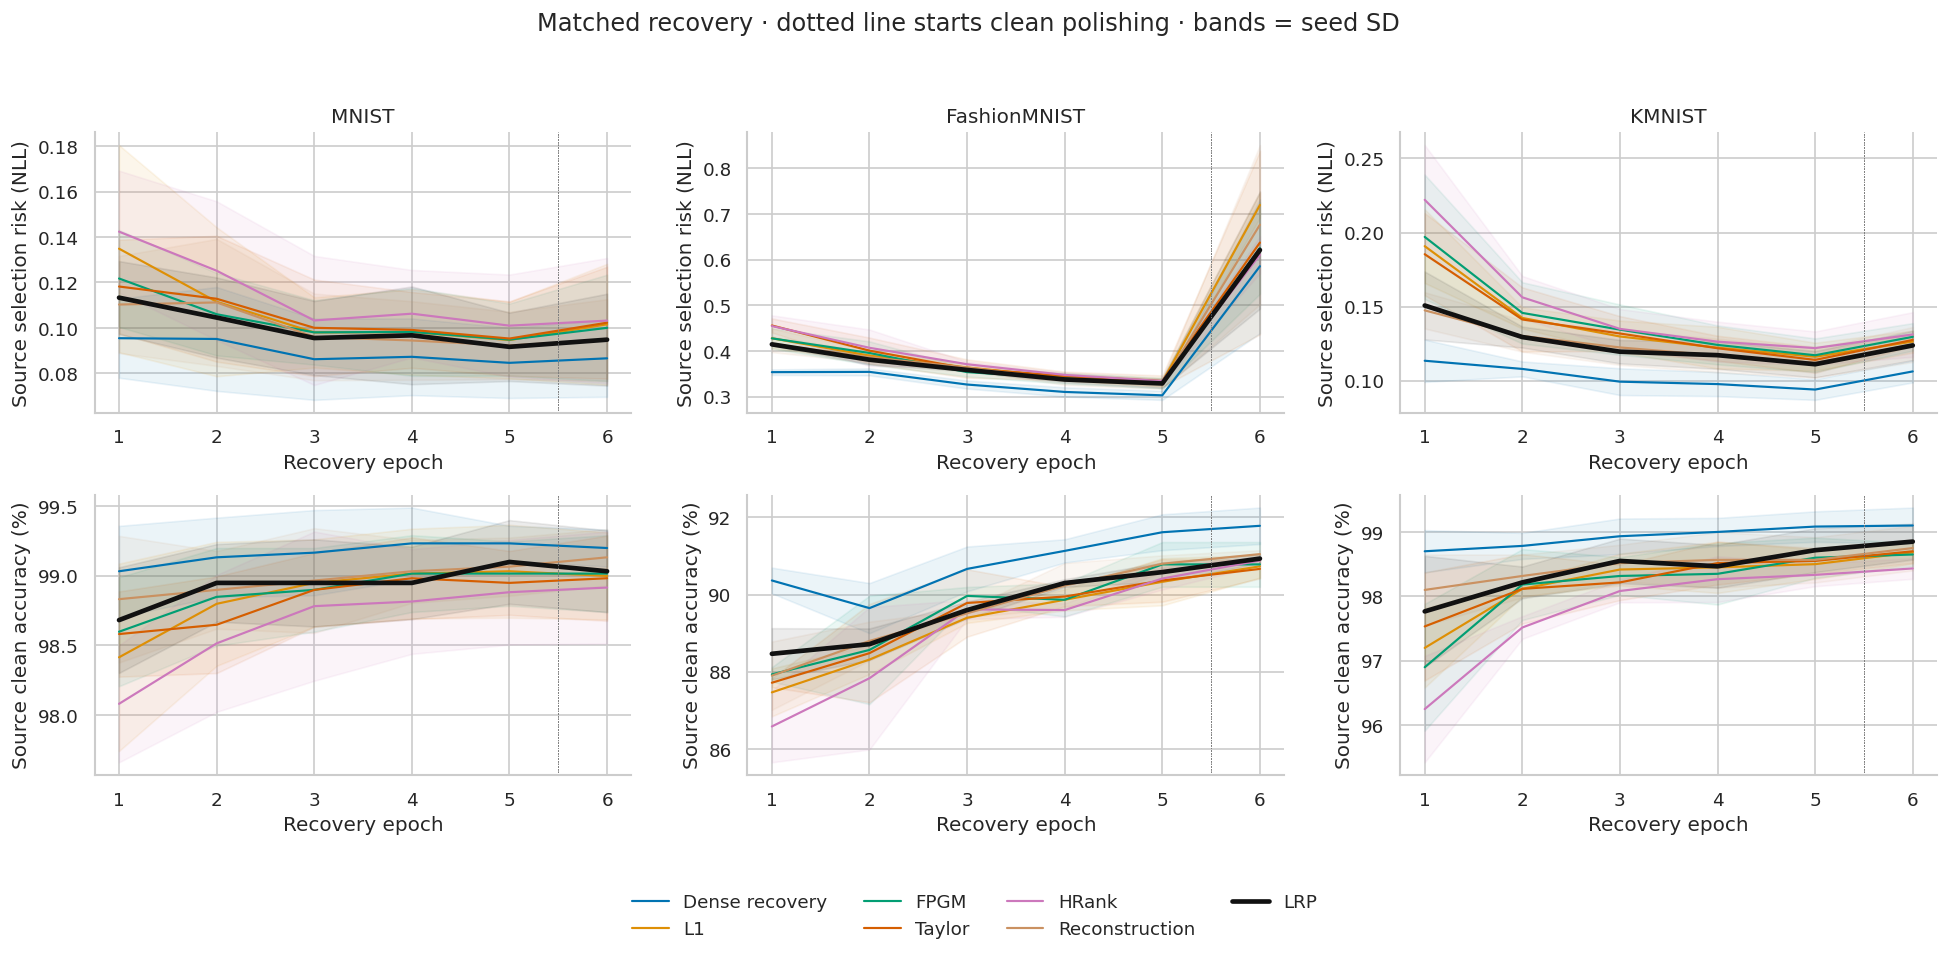

In [ ]:
# curves: common recovery and clean preservation
history=pd.DataFrame([{'dataset':r['dataset'],'seed':r['seed'],'method':r['method'],**row}
    for r in RECORDS for row in r['history']])
shown=('Dense recovery',*COMPRESSED); palette=dict(zip(shown,sns.color_palette('colorblind',len(shown))))
palette['LRP']='#111111'
fig,axes=plt.subplots(2,len(CFG.datasets),figsize=(5.5*len(CFG.datasets),8),squeeze=False)
for col,dataset in enumerate(CFG.datasets):
    for method in shown:
        g=history[(history.dataset==dataset)&(history.method==method)]
        for row,metric,label in [(0,'risk','Source selection risk (NLL)'),(1,'clean','Source clean accuracy (%)')]:
            h=g.groupby('epoch')[metric].agg(['mean','std']); x=h.index.to_numpy()
            m=h['mean'].to_numpy(); sd=h['std'].fillna(0).to_numpy()
            axes[row,col].plot(x,m,color=palette[method],label=method,lw=2.8 if method=='LRP' else 1.3)
            axes[row,col].fill_between(x,m-sd,m+sd,color=palette[method],alpha=.08)
            axes[row,col].set(title=dataset if row==0 else '',xlabel='Recovery epoch',ylabel=label)
            axes[row,col].axvline(CFG.recovery_epochs-CFG.clean_tail_epochs+.5,color='gray',ls=':',lw=.6)
handles,labels=axes[0,-1].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',ncol=4,frameon=False)
fig.suptitle('Matched recovery · dotted line starts clean polishing · bands = seed SD')
fig.tight_layout(rect=(0,.10,1,.95)); plt.show()


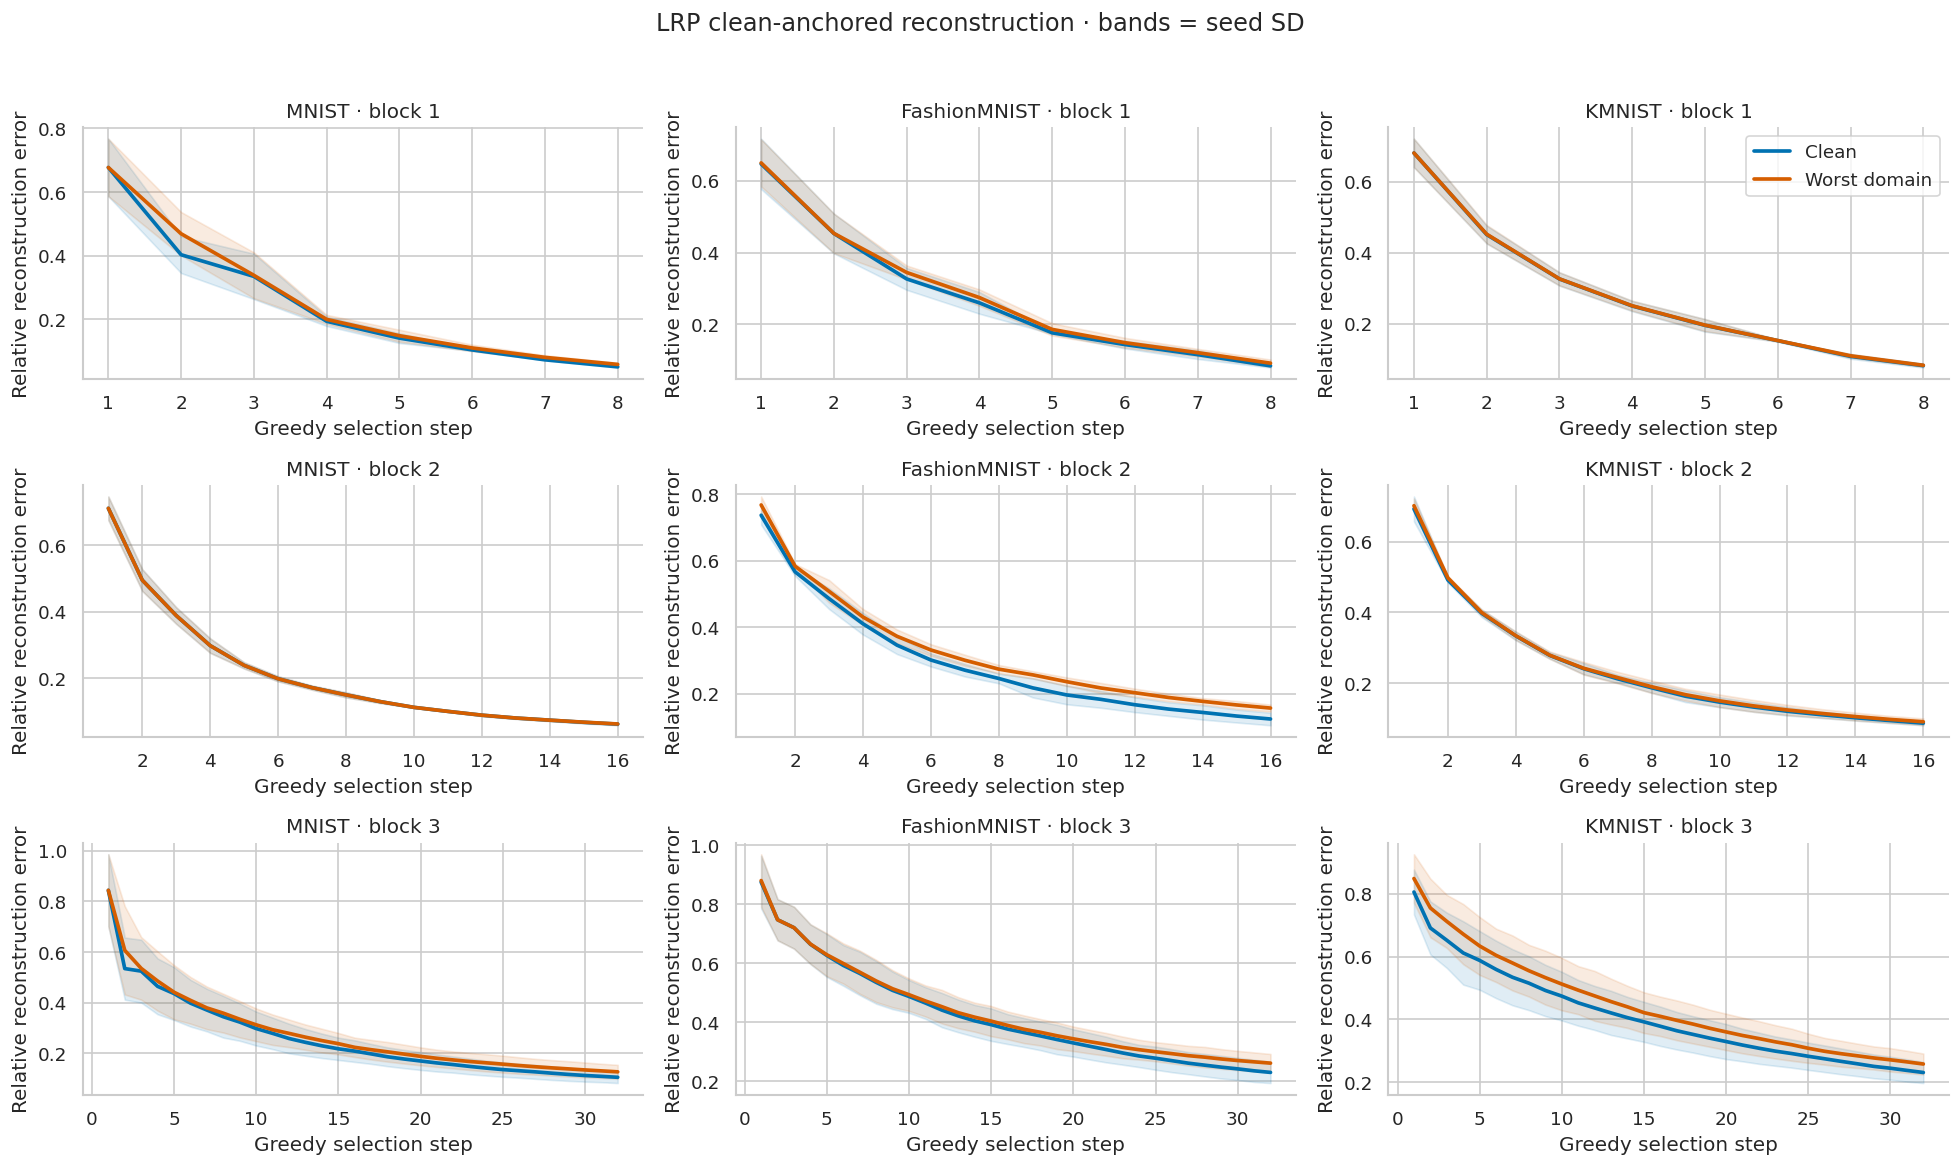

In [ ]:
# curves: clean and shifted reconstruction errors
PRUNING=pd.DataFrame([{'dataset':r['dataset'],'seed':r['seed'],'layer':layer['layer'],**item}
    for r in RECORDS if r['method']=='LRP' for layer in r['reconstruction'] for item in layer['trajectory']])
PRUNING['clean_error']=PRUNING.errors.map(lambda errors:errors[0])
fig,axes=plt.subplots(3*CFG.blocks_per_stage,len(CFG.datasets),
    figsize=(5.5*len(CFG.datasets),3.3*3*CFG.blocks_per_stage),squeeze=False)
for col,dataset in enumerate(CFG.datasets):
    for layer,ax in enumerate(axes[:,col]):
        g=PRUNING[(PRUNING.dataset==dataset)&(PRUNING.layer==layer)]
        for metric,label,color in [('clean_error','Clean','#0072B2'),('worst_error','Worst domain','#D55E00')]:
            h=g.groupby('kept')[metric].agg(['mean','std']); x=h.index.to_numpy()
            m=h['mean'].to_numpy(); sd=h['std'].fillna(0).to_numpy()
            ax.plot(x,m,color=color,lw=2.2,label=label)
            ax.fill_between(x,np.maximum(0,m-sd),m+sd,color=color,alpha=.12)
        ax.set(title=f'{dataset} · block {layer+1}',xlabel='Greedy selection step',ylabel='Relative reconstruction error')
axes[0,-1].legend(); fig.suptitle('LRP clean-anchored reconstruction · bands = seed SD')
fig.tight_layout(rect=(0,0,1,.96)); plt.show()


In [ ]:
# table: paired comparisons at the identical compression budget
paired=[]
for dataset in CFG.datasets:
    g=MODELS[MODELS.dataset==dataset]
    for baseline in CFG.baselines:
        p=g[g.method=='LRP'].merge(g[g.method==baseline],on=['dataset','seed','split_hash'],
            suffixes=('_lrp','_base'),validate='one_to_one')
        for endpoint in ('clean','corruption'):
            delta=p[endpoint+'_lrp']-p[endpoint+'_base']; n=len(delta)
            half=stats.t.ppf(.975,n-1)*stats.sem(delta) if n>1 else np.nan
            paired.append({'dataset':dataset,'baseline':baseline,'endpoint':endpoint,'seeds':n,
                'mean difference pp':delta.mean(),'positive seeds':int((delta>0).sum()),
                '95% descriptive t interval':f'[{delta.mean()-half:.2f}, {delta.mean()+half:.2f}]' if n>1 else 'n/a'})
display(pd.DataFrame(paired).round(3).style.hide(axis='index'))


dataset,baseline,endpoint,seeds,mean difference pp,positive seeds,95% descriptive t interval
MNIST,L1,clean,3,0.052000,2,"[-0.40, 0.50]"
MNIST,L1,corruption,3,0.264000,2,"[-3.04, 3.57]"
MNIST,FPGM,clean,3,-0.052000,1,"[-0.64, 0.54]"
MNIST,FPGM,corruption,3,0.191000,2,"[-4.28, 4.66]"
MNIST,Taylor,clean,3,-0.052000,1,"[-0.64, 0.54]"
MNIST,Taylor,corruption,3,0.628000,2,"[-0.98, 2.24]"
MNIST,HRank,clean,3,0.312000,2,"[-0.36, 0.98]"
MNIST,HRank,corruption,3,2.483000,3,"[-3.17, 8.14]"
MNIST,Reconstruction,clean,3,-0.104000,0,"[-0.55, 0.34]"
MNIST,Reconstruction,corruption,3,1.096000,3,"[-0.72, 2.91]"


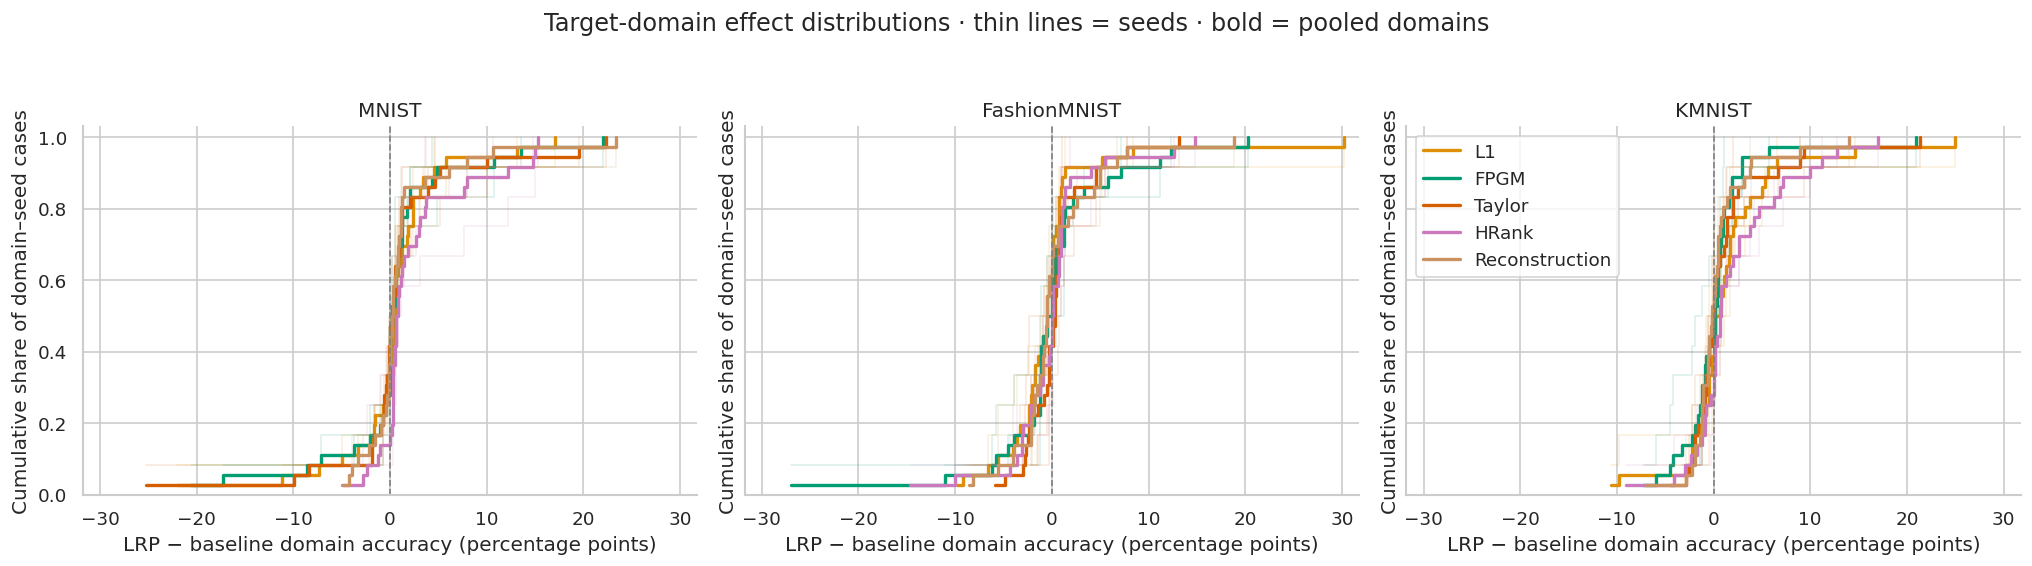

In [ ]:
# curves: distribution of paired target-domain effects
fig,axes=plt.subplots(1,len(CFG.datasets),figsize=(5.7*len(CFG.datasets),4.8),squeeze=False,sharex=True,sharey=True)
extent=1.
for ax,dataset in zip(axes[0],CFG.datasets):
    g=DOMAINS[(DOMAINS.dataset==dataset)&(DOMAINS['shift']!='clean')]
    for baseline in CFG.baselines:
        p=g[g.method=='LRP'].merge(g[g.method==baseline],on=['dataset','seed','shift','severity'],
            suffixes=('_lrp','_base'),validate='one_to_one')
        p['difference']=p.accuracy_lrp-p.accuracy_base
        for seed,part in p.groupby('seed'):
            values=np.sort(part.difference.to_numpy()); share=np.arange(1,len(values)+1)/len(values)
            ax.step(values,share,where='post',color=palette[baseline],alpha=.15,lw=.9)
        values=np.sort(p.difference.to_numpy()); share=np.arange(1,len(values)+1)/len(values)
        extent=max(extent,1.05*np.abs(values).max())
        ax.step(values,share,where='post',color=palette[baseline],lw=2.,label=baseline)
    ax.axvline(0,color='gray',ls='--',lw=1)
    ax.set(title=dataset,ylim=(0,1.03),xlabel='LRP − baseline domain accuracy (percentage points)',
           ylabel='Cumulative share of domain–seed cases')
axes[0,0].set_xlim(-extent,extent); axes[0,-1].legend()
fig.suptitle('Target-domain effect distributions · thin lines = seeds · bold = pooled domains')
fig.tight_layout(rect=(0,0,1,.94)); plt.show()


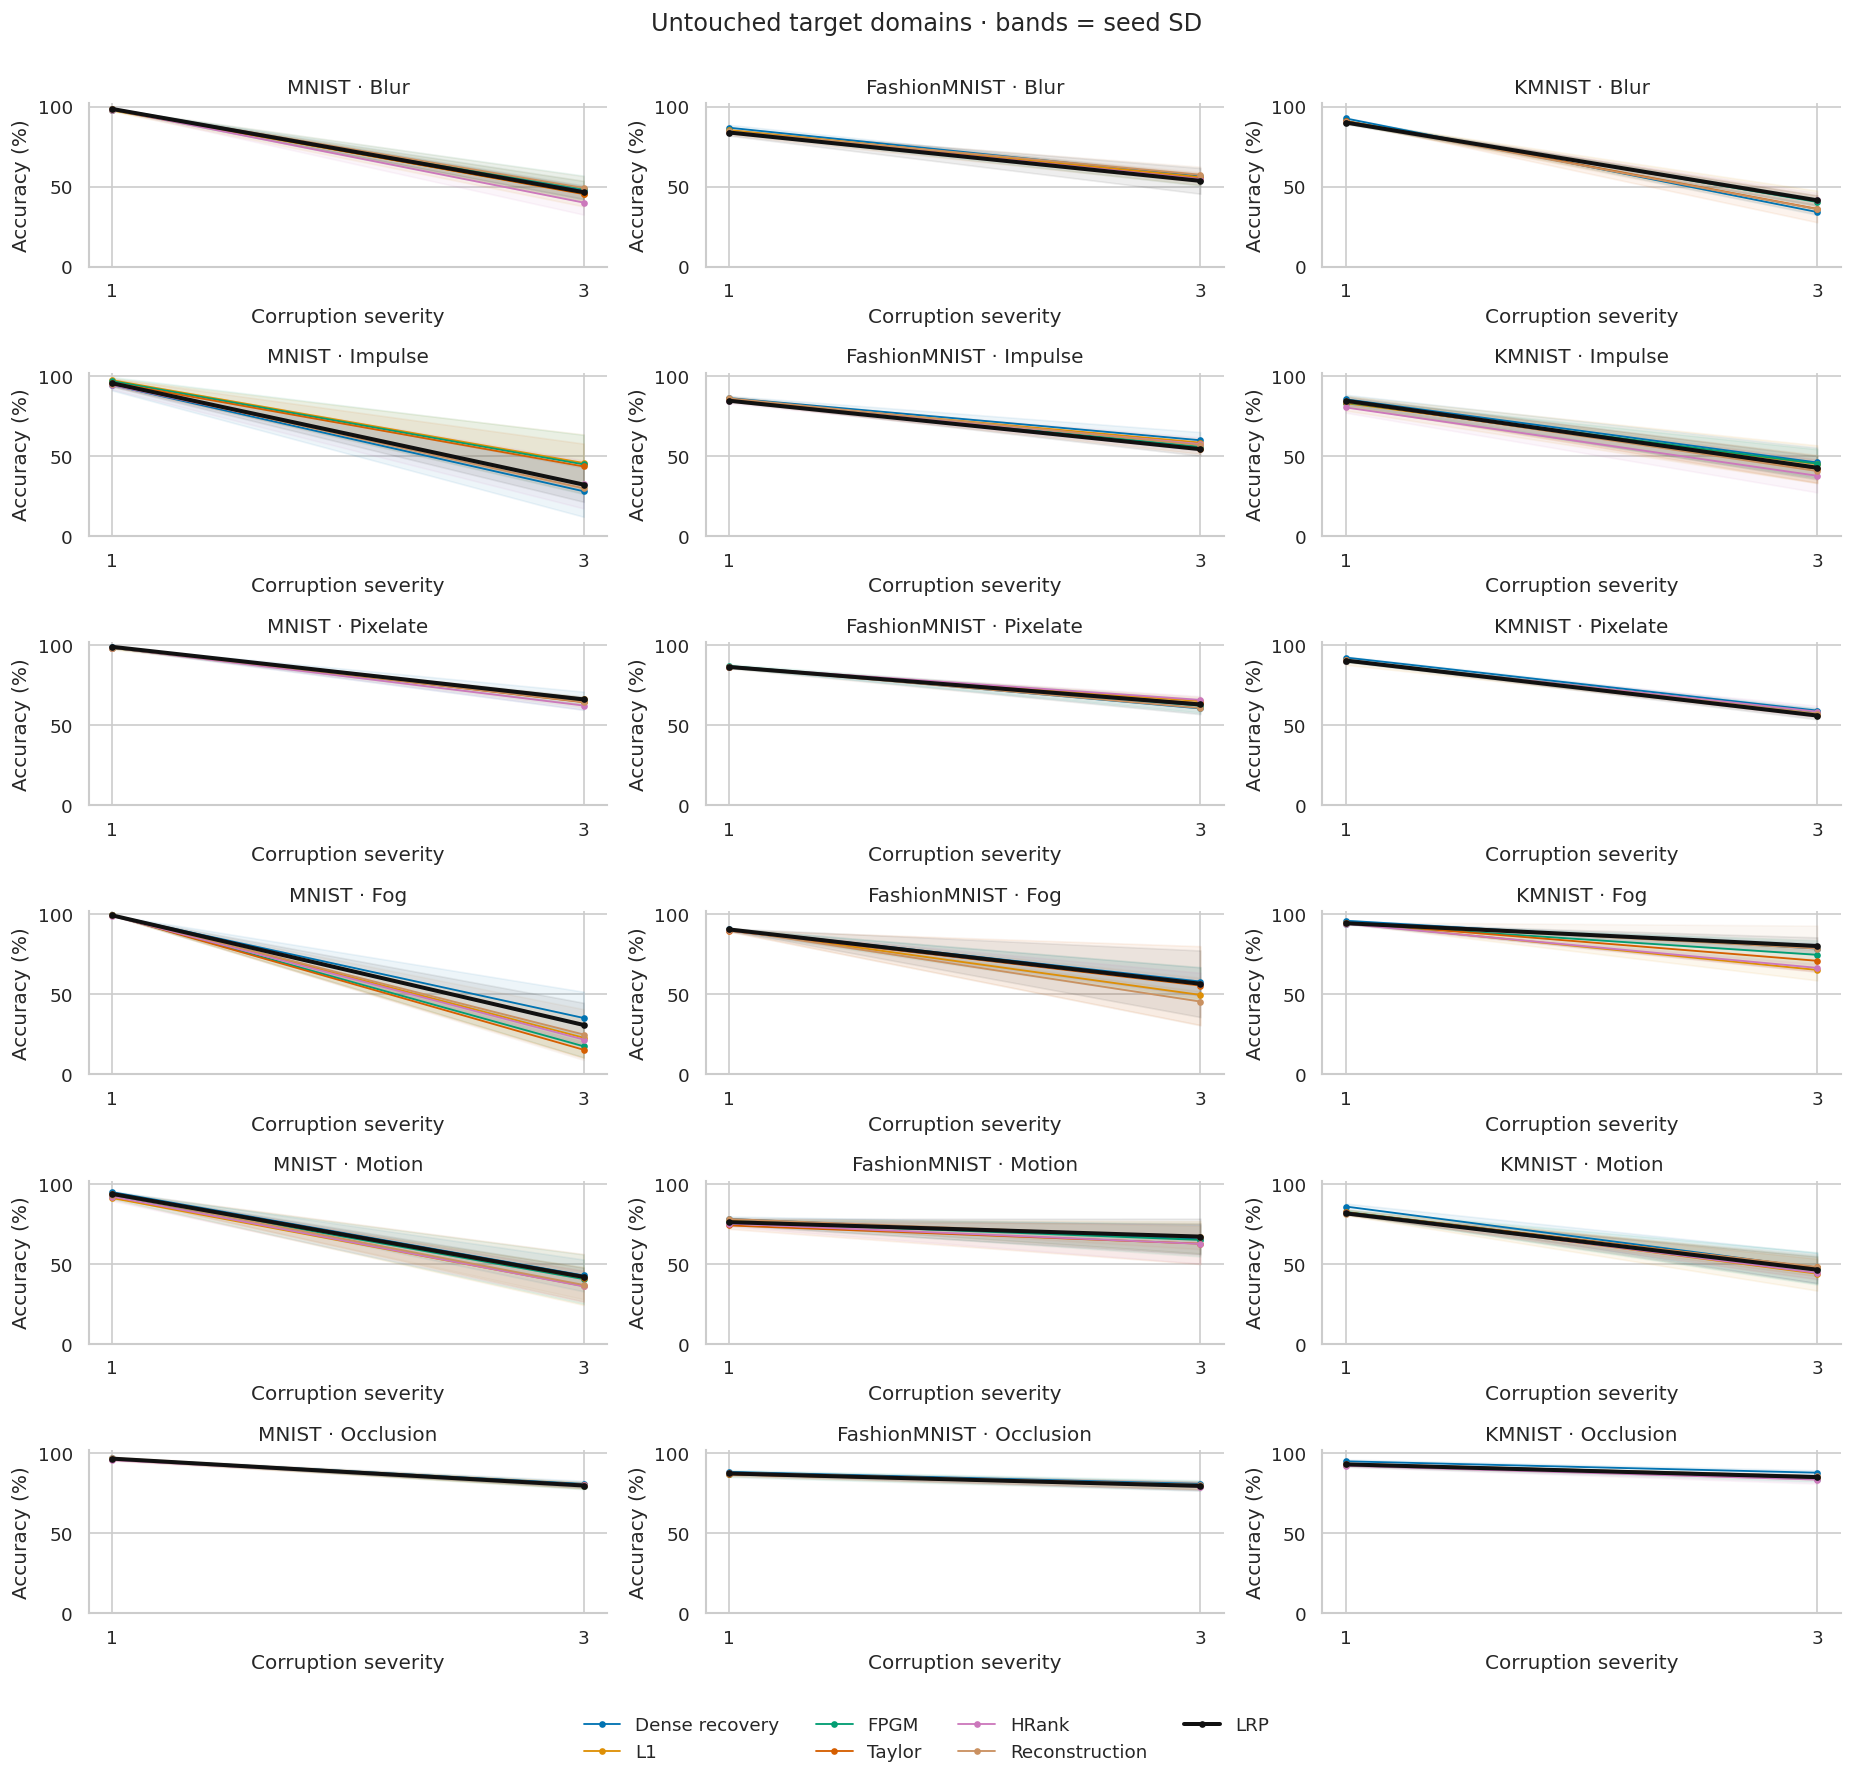

In [ ]:
# curves: corruption severity response by family
families=len(CFG.test_shifts)
fig,axes=plt.subplots(families,len(CFG.datasets),figsize=(5.2*len(CFG.datasets),2.5*families),squeeze=False)
for col,dataset in enumerate(CFG.datasets):
    for row,kind in enumerate(CFG.test_shifts):
        ax=axes[row,col]
        for method in ('Dense recovery',*COMPRESSED):
            g=DOMAINS[(DOMAINS.dataset==dataset)&(DOMAINS.method==method)&(DOMAINS['shift']==kind)]
            h=g.groupby('severity').accuracy.agg(['mean','std']); x=h.index.to_numpy()
            m=h['mean'].to_numpy(); sd=h['std'].fillna(0).to_numpy()
            ax.plot(x,m,color=palette[method],marker='o',ms=3,lw=2.4 if method=='LRP' else 1.1,label=method)
            ax.fill_between(x,np.maximum(0,m-sd),np.minimum(100,m+sd),color=palette[method],alpha=.07)
        ax.set(title=f'{dataset} · {kind.title()}',xlabel='Corruption severity',ylabel='Accuracy (%)',
               xticks=CFG.severities,ylim=(0,102))
handles,labels=axes[0,-1].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',ncol=4,frameon=False)
fig.suptitle('Untouched target domains · bands = seed SD')
fig.tight_layout(rect=(0,.045,1,.98)); plt.show()


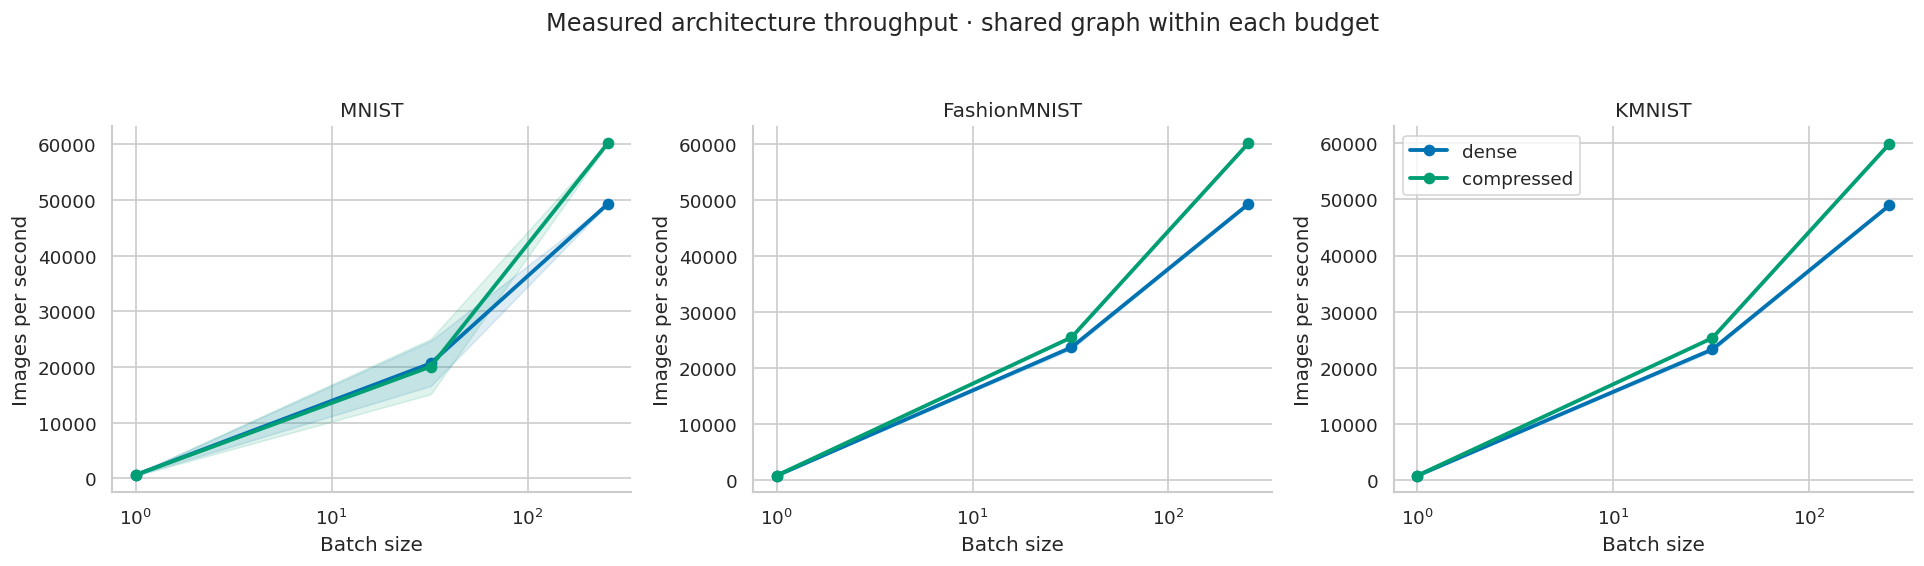

In [ ]:
# curves: measured throughput with paired timing
timing_rows=[]
for dataset in CFG.datasets:
    for seed in CFG.seeds:
        profiles=json.loads((RUN_DIR/dataset/f'seed_{seed}'/'architecture_profiles.json').read_text())
        for architecture,profile in profiles.items():
            timing_rows.extend({'dataset':dataset,'seed':seed,'architecture':architecture,
                               'throughput':1000*r['batch']/r['ms'],**r} for r in profile['timings'])
TIMINGS=pd.DataFrame(timing_rows)
fig,axes=plt.subplots(1,len(CFG.datasets),figsize=(5.4*len(CFG.datasets),4.8),squeeze=False)
for ax,dataset in zip(axes[0],CFG.datasets):
    for architecture,color in [('dense','#0072B2'),('compressed','#009E73')]:
        g=TIMINGS[(TIMINGS.dataset==dataset)&(TIMINGS.architecture==architecture)]
        h=g.groupby(['seed','batch']).throughput.median().reset_index().groupby('batch').throughput.agg(['mean','std'])
        x=h.index.to_numpy(); m=h['mean'].to_numpy(); sd=h['std'].fillna(0).to_numpy()
        ax.plot(x,m,marker='o',color=color,lw=2.3,label=architecture)
        ax.fill_between(x,np.maximum(0,m-sd),m+sd,color=color,alpha=.12)
    ax.set(title=dataset,xlabel='Batch size',ylabel='Images per second',xscale='log')
axes[0,-1].legend(); fig.suptitle('Measured architecture throughput · shared graph within each budget')
fig.tight_layout(rect=(0,0,1,.94)); plt.show()


In [ ]:
# source checkpoint audit and inline raw results
audit=[]
for record in RECORDS:
    if record['method']=='Teacher': continue
    audit.append({'dataset':record['dataset'],'seed':record['seed'],'method':record['method'],
        'selected_epoch':record['selected_epoch'],'source audit clean %':record['audit_source']['clean'],
        'source audit shifted %':record['audit_source']['shift_mean'],
        'criterion seconds':record['search_seconds'],'recovery seconds':record['recovery_seconds']})
display(pd.DataFrame(audit).round(3).style.hide(axis='index'))
from IPython.display import JSON
payload={'config':asdict(CFG),'methods':METHODS,'records':RECORDS,'prior_test_usage':PRIOR_TEST_USAGE,
    'primary_endpoint':'frozen mean corruption accuracy on untouched test images',
    'matching':'same hidden widths, parameter/MAC budget, recovery batches, loss, epochs, LR and source selection',
    'baseline_status':'criterion adaptations to the common backbone; not official-paper reproductions',
    'status':'measured; no assumed superiority'}
atomic_json(payload,RUN_DIR/'all_results.json')
MODELS.to_csv(RUN_DIR/'models.csv',index=False); DOMAINS.to_csv(RUN_DIR/'domains.csv',index=False)
display(JSON(payload,expanded=False))
print('Download the executed .ipynb to keep all inline results. Checkpoints remain in the runtime.')


dataset,seed,method,selected_epoch,source audit clean %,source audit shifted %,criterion seconds,recovery seconds
MNIST,0,Dense recovery,5,99.325000,99.371000,0.009000,57.858000
MNIST,0,L1,5,99.325000,99.242000,0.095000,41.433000
MNIST,0,FPGM,5,99.375000,99.354000,0.034000,41.423000
MNIST,0,Taylor,5,99.225000,99.205000,0.165000,41.991000
MNIST,0,HRank,5,99.200000,99.192000,1.026000,41.775000
MNIST,0,Reconstruction,5,99.325000,99.200000,0.959000,42.220000
MNIST,0,LRP,4,99.325000,99.234000,2.408000,41.688000
MNIST,1,Dense recovery,5,99.225000,99.117000,0.010000,57.729000
MNIST,1,L1,5,99.125000,99.021000,0.036000,41.108000
MNIST,1,FPGM,5,99.150000,99.055000,0.027000,41.071000


<IPython.core.display.JSON object>

Download the executed .ipynb to keep all inline results. Checkpoints remain in the runtime.


In [ ]:
# references
# L1 criterion: https://arxiv.org/abs/1608.08710
# FPGM criterion: https://arxiv.org/abs/1811.00250
# First-order Taylor criterion: https://arxiv.org/abs/1611.06440
# HRank criterion: https://arxiv.org/abs/2002.10179
# Reconstruction control: clean-domain group greedy ridge selection and sequential refitting.
# LRP has one configuration. Every recovered comparison uses the identical training objective.
